# YOLOv5s Training on RDD2022

This notebook trains **YOLOv5s** on the RDD2022 road damage dataset (5 classes) using the official YOLOv5 repository from Ultralytics. The same settings are used for YOLOv8n and YOLOv8s so the three models can be compared fairly: image size 640, batch size 16, 50 epochs, early-stopping patience 15 and seed 42.

**Steps:** environment, dataset checks, YOLOv5 setup, training, results.

*Runs on Kaggle with a GPU. The data is the Kaggle YOLO-format version of RDD2022.*

## 1. Environment and random seed

Checks Python, PyTorch and the GPU, then fixes the random seed (42) so runs can be repeated.

In [46]:
import os
import platform
import torch

print("Python version:", platform.python_version())
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
print("CPU cores:", os.cpu_count())

if not torch.cuda.is_available():
    raise RuntimeError(
        "GPU is not enabled. Open Kaggle notebook settings "
        "and select GPU P100 or GPU T4."
    )

for device_index in range(torch.cuda.device_count()):
    print(
        f"GPU {device_index}:",
        torch.cuda.get_device_name(device_index)
    )

Python version: 3.12.13
PyTorch version: 2.10.0+cu128
CUDA available: True
GPU count: 2
CPU cores: 4
GPU 0: Tesla T4
GPU 1: Tesla T4


In [47]:
import os
import random
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import torch
import matplotlib.pyplot as plt

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed(SEED)
    torch.cuda.manual_seed_all(SEED)

print("Random seed:", SEED)

Random seed: 42


## 2. Paths and dataset checks

Sets the paths, then checks that the folder structure is complete, that every image has a label file (and the other way round), and that the class IDs are only 0 to 4. It also looks for invalid or duplicate label lines and writes the dataset YAML used for training.

In [48]:
from pathlib import Path

SOURCE_DATASET = Path(
    "/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT"
)

WORKING_DIRECTORY = Path("/kaggle/working")

YOLOV5_DIRECTORY = WORKING_DIRECTORY / "yolov5"

PROJECT_DIRECTORY = (
    WORKING_DIRECTORY / "RoadDamageProject"
)

RUN_NAME = "YOLOv5s_RDD2022_5class"

RUN_DIRECTORY = PROJECT_DIRECTORY / RUN_NAME

YAML_PATH = WORKING_DIRECTORY / "rdd2022_5class.yaml"

print("Dataset:", SOURCE_DATASET)
print("YOLOv5 repository:", YOLOV5_DIRECTORY)
print("Project directory:", PROJECT_DIRECTORY)
print("Run directory:", RUN_DIRECTORY)
print("YAML path:", YAML_PATH)

Dataset: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
YOLOv5 repository: /kaggle/working/yolov5
Project directory: /kaggle/working/RoadDamageProject
Run directory: /kaggle/working/RoadDamageProject/YOLOv5s_RDD2022_5class
YAML path: /kaggle/working/rdd2022_5class.yaml


In [49]:
required_directories = [
    SOURCE_DATASET / "train" / "images",
    SOURCE_DATASET / "train" / "labels",
    SOURCE_DATASET / "val" / "images",
    SOURCE_DATASET / "val" / "labels",
    SOURCE_DATASET / "test" / "images",
    SOURCE_DATASET / "test" / "labels",
]

for directory in required_directories:
    print(
        directory,
        "->",
        "FOUND" if directory.exists() else "MISSING"
    )

missing_directories = [
    directory
    for directory in required_directories
    if not directory.exists()
]

if missing_directories:
    raise FileNotFoundError(
        f"Missing dataset directories: {missing_directories}"
    )

/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/images -> FOUND
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/train/labels -> FOUND
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/images -> FOUND
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/val/labels -> FOUND
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/images -> FOUND
/kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT/test/labels -> FOUND


In [50]:
IMAGE_EXTENSIONS = {
    ".jpg",
    ".jpeg",
    ".png",
    ".bmp",
    ".webp"
}

dataset_counts = []

for split in ["train", "val", "test"]:
    image_directory = SOURCE_DATASET / split / "images"
    label_directory = SOURCE_DATASET / split / "labels"

    image_files = [
        path
        for path in image_directory.iterdir()
        if path.suffix.lower() in IMAGE_EXTENSIONS
    ]

    label_files = list(label_directory.glob("*.txt"))

    dataset_counts.append(
        {
            "Split": split,
            "Images": len(image_files),
            "Label files": len(label_files)
        }
    )

counts_dataframe = pd.DataFrame(dataset_counts)

display(counts_dataframe)

,Split,Images,Label files
0,train,26869,26869
1,val,5758,5758
2,test,5758,5758


In [51]:
matching_results = []

for split in ["train", "val", "test"]:
    image_directory = SOURCE_DATASET / split / "images"
    label_directory = SOURCE_DATASET / split / "labels"

    image_stems = {
        path.stem
        for path in image_directory.iterdir()
        if path.suffix.lower() in IMAGE_EXTENSIONS
    }

    label_stems = {
        path.stem
        for path in label_directory.glob("*.txt")
    }

    images_without_labels = image_stems - label_stems
    labels_without_images = label_stems - image_stems

    matching_results.append(
        {
            "Split": split,
            "Images without label files": len(
                images_without_labels
            ),
            "Labels without images": len(
                labels_without_images
            )
        }
    )

display(pd.DataFrame(matching_results))

,Split,Images without label files,Labels without images
0,train,0,0
1,val,0,0
2,test,0,0


In [8]:
VALID_CLASS_IDS = {0, 1, 2, 3, 4}

class_counts = {
    class_id: 0
    for class_id in sorted(VALID_CLASS_IDS)
}

invalid_annotations = []
duplicate_annotations = []

for split in ["train", "val", "test"]:
    label_directory = SOURCE_DATASET / split / "labels"

    for label_path in label_directory.glob("*.txt"):
        lines = label_path.read_text(
            encoding="utf-8"
        ).splitlines()

        seen_annotations = set()

        for line_number, line in enumerate(lines, start=1):
            line = line.strip()

            if not line:
                continue

            if line in seen_annotations:
                duplicate_annotations.append(
                    {
                        "split": split,
                        "file": str(label_path),
                        "line": line_number,
                        "annotation": line
                    }
                )

            seen_annotations.add(line)

            parts = line.split()

            if len(parts) != 5:
                invalid_annotations.append(
                    {
                        "split": split,
                        "file": str(label_path),
                        "line": line_number,
                        "annotation": line,
                        "reason": "Expected five values"
                    }
                )
                continue

            try:
                class_id = int(float(parts[0]))
                x_center, y_center, width, height = map(
                    float,
                    parts[1:]
                )
            except ValueError:
                invalid_annotations.append(
                    {
                        "split": split,
                        "file": str(label_path),
                        "line": line_number,
                        "annotation": line,
                        "reason": "Non-numeric value"
                    }
                )
                continue

            if class_id not in VALID_CLASS_IDS:
                invalid_annotations.append(
                    {
                        "split": split,
                        "file": str(label_path),
                        "line": line_number,
                        "annotation": line,
                        "reason": f"Invalid class ID {class_id}"
                    }
                )
                continue

            if not (
                0 <= x_center <= 1
                and 0 <= y_center <= 1
                and 0 < width <= 1
                and 0 < height <= 1
            ):
                invalid_annotations.append(
                    {
                        "split": split,
                        "file": str(label_path),
                        "line": line_number,
                        "annotation": line,
                        "reason": "Invalid normalized bounding box"
                    }
                )
                continue

            class_counts[class_id] += 1

print("Class counts:")
for class_id, count in class_counts.items():
    print(f"Class {class_id}: {count:,}")

print("\nInvalid annotation rows:", len(invalid_annotations))
print("Duplicate annotation rows:", len(duplicate_annotations))

Class counts:
Class 0: 26,016
Class 1: 11,830
Class 2: 10,616
Class 3: 10,705
Class 4: 6,544

Invalid annotation rows: 1
Duplicate annotation rows: 3


In [53]:
dataset_configuration = {
    "path": str(SOURCE_DATASET),
    "train": "train/images",
    "val": "val/images",
    "test": "test/images",
    "nc": 5,
    "names": [
        "longitudinal crack",
        "transverse crack",
        "alligator crack",
        "other corruption",
        "Pothole"
    ]
}

with open(
    YAML_PATH,
    "w",
    encoding="utf-8"
) as yaml_file:
    yaml.safe_dump(
        dataset_configuration,
        yaml_file,
        sort_keys=False,
        allow_unicode=True
    )

print(YAML_PATH.read_text(encoding="utf-8"))

path: /kaggle/input/datasets/aliabdelmenam/rdd-2022/RDD_SPLIT
train: train/images
val: val/images
test: test/images
nc: 5
names:
- longitudinal crack
- transverse crack
- alligator crack
- other corruption
- Pothole



## 3. Set up YOLOv5

Clones the official YOLOv5 repository, records the commit that was used (so the run can be reproduced), installs its requirements and checks that it can be imported.

In [54]:
import subprocess
from pathlib import Path

if not YOLOV5_DIRECTORY.exists():
    subprocess.run(
        [
            "git",
            "clone",
            "https://github.com/ultralytics/yolov5.git",
            str(YOLOV5_DIRECTORY)
        ],
        check=True
    )

    print("YOLOv5 repository cloned.")
else:
    print("YOLOv5 repository already exists.")

YOLOv5 repository already exists.


In [55]:
import subprocess

commit_hash = subprocess.check_output(
    [
        "git",
        "-C",
        str(YOLOV5_DIRECTORY),
        "rev-parse",
        "HEAD"
    ],
    text=True
).strip()

print("YOLOv5 commit:", commit_hash)

YOLOv5 commit: 20d1d78a08277e365d57bfa3a2cce752772d9e59


In [56]:
import subprocess
import sys

subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "-q",
        "-r",
        str(YOLOV5_DIRECTORY / "requirements.txt")
    ],
    check=True
)

print("YOLOv5 requirements installed.")

YOLOv5 requirements installed.


In [57]:
import sys

sys.path.insert(
    0,
    str(YOLOV5_DIRECTORY)
)

from models.common import DetectMultiBackend

print("YOLOv5 import successful.")

YOLOv5 import successful.


## 4. Training configuration

Chooses the number of data-loader workers from the available CPU cores and puts the training settings in one table. The next cells let the run **resume** from its last checkpoint if a Kaggle session stopped (or start fresh with `START_FRESH = True`) and check for the pretrained weights.

In [58]:
import os

available_cpu_cores = os.cpu_count() or 2

if available_cpu_cores >= 8:
    NUM_WORKERS = 8
elif available_cpu_cores >= 4:
    NUM_WORKERS = 4
else:
    NUM_WORKERS = 2

print("Available CPU cores:", available_cpu_cores)
print("Data-loader workers:", NUM_WORKERS)

Available CPU cores: 4
Data-loader workers: 4


In [59]:
EPOCHS = 50
IMAGE_SIZE = 640
BATCH_SIZE = 16
PATIENCE = 15
SAVE_PERIOD = 5


DEVICE = "0"
CACHE = "ram"

training_configuration = {
    "model": "yolov5s.pt",
    "epochs": EPOCHS,
    "image_size": IMAGE_SIZE,
    "batch_size": BATCH_SIZE,
    "workers": NUM_WORKERS,
    "device": DEVICE,
    "cache": CACHE,
    "patience": PATIENCE,
    "seed": SEED,
    "save_period": SAVE_PERIOD,
    "run_name": RUN_NAME
}

display(
    pd.DataFrame(
        training_configuration.items(),
        columns=["Setting", "Value"]
    )
)

print("DEVICE:", DEVICE)
print("DEVICE type:", type(DEVICE))

,Setting,Value
0,model,yolov5s.pt
1,epochs,50
2,image_size,640
3,batch_size,16
4,workers,4
5,device,0
6,cache,ram
7,patience,15
8,seed,42
9,save_period,5


DEVICE: 0
DEVICE type: <class 'str'>


In [60]:
import shutil
from pathlib import Path

# --- Auto-continue across Kaggle sessions ---


if RUN_DIRECTORY.exists():
    print("RUN_DIRECTORY already populated in this session, skipping restore:", RUN_DIRECTORY)
else:
    candidates = [
        p for p in Path("/kaggle/input").rglob(RUN_NAME)
        if p.is_dir()
        and p.parent.name == "RoadDamageProject"
        and (p / "weights" / "last.pt").exists()
    ]
    candidates = sorted(
        candidates,
        key=lambda p: (p / "weights" / "last.pt").stat().st_mtime,
        reverse=True
    )

    if candidates:
        previous_run_source = candidates[0]
        shutil.copytree(previous_run_source, RUN_DIRECTORY)
        print("Auto-restored previous run:")
        print("  from:", previous_run_source)
        print("  to:  ", RUN_DIRECTORY)

        if len(candidates) > 1:
            print(
                f"\nNote: found {len(candidates)} matching inputs, "
                "used the most recently modified one:"
            )
            for c in candidates:
                print(" -", c)
    else:
        print(
            "No previous checkpoint found under /kaggle/input. "
            "Starting fresh (or add the previous session's output "
            "as an input if you meant to resume)."
        )

RUN_DIRECTORY already populated in this session, skipping restore: /kaggle/working/RoadDamageProject/YOLOv5s_RDD2022_5class


In [62]:
import shutil

# Set this to True only when you want to throw away any previous
# progress on this RUN_NAME and start epoch 1 from scratch again.
# Leave it False to automatically continue an interrupted run.
START_FRESH = False
# START_FRESH = True

LAST_WEIGHTS = RUN_DIRECTORY / "weights" / "last.pt"

if START_FRESH and RUN_DIRECTORY.exists():
    shutil.rmtree(RUN_DIRECTORY)
    print("Previous run directory removed. Starting fresh.")
    RESUME_TRAINING = False
elif LAST_WEIGHTS.exists():
    print("Found existing checkpoint:", LAST_WEIGHTS)
    print("Training will resume from where it left off.")
    RESUME_TRAINING = True
else:
    print("No previous checkpoint found. Starting a new run.")
    RESUME_TRAINING = False

PROJECT_DIRECTORY.mkdir(
    parents=True,
    exist_ok=True
)

print("Run directory:", RUN_DIRECTORY)
print("Resume training:", RESUME_TRAINING)

Found existing checkpoint: /kaggle/working/RoadDamageProject/YOLOv5s_RDD2022_5class/weights/last.pt
Training will resume from where it left off.
Run directory: /kaggle/working/RoadDamageProject/YOLOv5s_RDD2022_5class
Resume training: True


In [63]:
import subprocess
import sys

pretrained_weights = (
    YOLOV5_DIRECTORY / "yolov5s.pt"
)

if pretrained_weights.exists():
    print(
        "Pretrained weights already exist:",
        pretrained_weights
    )
else:
    print(
        "Weights will be downloaded automatically "
        "when training starts."
    )

Weights will be downloaded automatically when training starts.


## 5. Train YOLOv5s

Runs the YOLOv5 training script with the settings above, or resumes the previous run if one was interrupted.

In [64]:
import subprocess
import sys
import time

if RESUME_TRAINING:
    # When resuming, YOLOv5 reads the original run's opt.yaml
    # (data, img size, batch size, device, cache, epochs, etc.) and the
    # optimizer/scheduler state from last.pt automatically, so we
    # only pass --resume. It will continue from the next epoch
    # (e.g. epoch 21 if it stopped after epoch 20) up to the
    # original target epoch count, using the same cache setting
    # the original run started with.
    training_command = [
        str(sys.executable),
        str(YOLOV5_DIRECTORY / "train.py"),

        "--resume",
        str(LAST_WEIGHTS),
    ]
else:
    training_command = [
        str(sys.executable),
        str(YOLOV5_DIRECTORY / "train.py"),

        "--weights",
        "yolov5s.pt",

        "--data",
        str(YAML_PATH),

        "--epochs",
        str(EPOCHS),

        "--img",
        str(IMAGE_SIZE),

        "--batch-size",
        str(BATCH_SIZE),

        "--workers",
        str(NUM_WORKERS),

        "--device",
        DEVICE,

        "--cache",
        CACHE,

        "--patience",
        str(PATIENCE),

        "--seed",
        str(SEED),

        "--save-period",
        str(SAVE_PERIOD),

        "--project",
        str(PROJECT_DIRECTORY),

        "--name",
        str(RUN_NAME),

        "--exist-ok"
    ]

print("Training command:")
print(" ".join(training_command))

training_start_time = time.time()

training_process = subprocess.run(
    training_command,
    cwd=str(YOLOV5_DIRECTORY)
)

training_duration_hours = (
    time.time() - training_start_time
) / 3600

print("\nTraining return code:", training_process.returncode)
print(
    "Training duration:",
    f"{training_duration_hours:.2f} hours"
)

if training_process.returncode == 0:
    print("Training finished successfully.")
else:
    print(
        "Training did not exit normally. "
        "Check the training log and saved checkpoints."
    )

Training command:
/usr/bin/python3 /kaggle/working/yolov5/train.py --resume /kaggle/working/RoadDamageProject/YOLOv5s_RDD2022_5class/weights/last.pt
WARNING ⚠️ wandb: wandb is deprecated and will be removed in a future release. See supported integrations at https://github.com/ultralytics/yolov5#integrations.
train: weights=yolov5s.pt, cfg=, data=data/coco128.yaml, hyp=data/hyps/hyp.scratch-low.yaml, epochs=100, batch_size=16, imgsz=640, rect=False, resume=/kaggle/working/RoadDamageProject/YOLOv5s_RDD2022_5class/weights/last.pt, nosave=False, noval=False, noautoanchor=False, noplots=False, evolve=None, evolve_population=data/hyps, resume_evolve=None, bucket=, cache=None, image_weights=False, device=, multi_scale=False, single_cls=False, optimizer=SGD, sync_bn=False, workers=8, project=runs/train, name=exp, exist_ok=False, quad=False, cos_lr=False, label_smoothing=0.0, patience=100, freeze=[0], save_period=-1, seed=0, local_rank=-1, entity=None, upload_dataset=False, bbox_interval=-1
git

/kaggle/working/yolov5/train.py:344: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler(enabled=amp)


Image sizes 640 train, 640 val
Using 4 dataloader workers
Logging results to /kaggle/working/RoadDamageProject/YOLOv5s_RDD2022_5class
Starting training for 50 epochs...

      Epoch    GPU_mem   box_loss   obj_loss   cls_loss  Instances       Size
      39/49      3.42G    0.04616    0.01745   0.007709         17        640: 100% ━━━━━━━━━━━━ 1680/1680 2.3it/s 12:200.4ss
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 180/180 3.6it/s 49.5s0.3ss
                   all       5758       9740      0.627      0.561      0.587      0.289

      Epoch    GPU_mem   box_loss   obj_loss   cls_loss  Instances       Size
      40/49      4.32G    0.04589    0.01731    0.00746         12        640: 100% ━━━━━━━━━━━━ 1680/1680 2.3it/s 12:190.2ss
                 Class     Images  Instances          P          R      mAP50   mAP50-95: 100% ━━━━━━━━━━━━ 180/180 3.7it/s 48.7s0.3ss
                   all       5758       9740       0.63      0

## 6. Check the training outputs

Confirms that the best weights, last weights and `results.csv` exist, loads the results of every epoch, shows the last completed epoch and picks out the Precision, Recall and mAP columns.

In [66]:
BEST_WEIGHTS = (
    RUN_DIRECTORY / "weights" / "best.pt"
)

LAST_WEIGHTS = (
    RUN_DIRECTORY / "weights" / "last.pt"
)

RESULTS_CSV = (
    RUN_DIRECTORY / "results.csv"
)

print("Run directory exists:", RUN_DIRECTORY.exists())
print("Best weights exist:", BEST_WEIGHTS.exists())
print("Last weights exist:", LAST_WEIGHTS.exists())
print("Results CSV exists:", RESULTS_CSV.exists())

if RUN_DIRECTORY.exists():
    print("\nRun directory contents:")

    for path in sorted(RUN_DIRECTORY.iterdir()):
        print(path.name)

if (RUN_DIRECTORY / "weights").exists():
    print("\nWeight files:")

    for path in sorted(
        (RUN_DIRECTORY / "weights").iterdir()
    ):
        size_mb = path.stat().st_size / (1024 ** 2)

        print(
            path.name,
            "-",
            f"{size_mb:.2f} MB"
        )

Run directory exists: True
Best weights exist: True
Last weights exist: True
Results CSV exists: True

Run directory contents:
F1_curve.png
PR_curve.png
P_curve.png
R_curve.png
confusion_matrix.png
events.out.tfevents.1786315568.5cbb4492445e.142.0
events.out.tfevents.1786368955.8568a571fb31.146.0
events.out.tfevents.1786402379.d5d5e3540cd0.133.0
events.out.tfevents.1786403108.d5d5e3540cd0.259.0
events.out.tfevents.1786450408.09cef5d130e1.176.0
events.out.tfevents.1786450818.09cef5d130e1.301.0
hyp.yaml
labels.jpg
labels_correlogram.jpg
opt.yaml
results.csv
results.png
train_batch0.jpg
train_batch1.jpg
train_batch2.jpg
val_batch0_labels.jpg
val_batch0_pred.jpg
val_batch1_labels.jpg
val_batch1_pred.jpg
val_batch2_labels.jpg
val_batch2_pred.jpg
weights

Weight files:
best.pt - 13.79 MB
epoch0.pt - 54.29 MB
epoch10.pt - 54.30 MB
epoch15.pt - 54.30 MB
epoch20.pt - 54.30 MB
epoch25.pt - 54.30 MB
epoch30.pt - 54.30 MB
epoch35.pt - 54.30 MB
epoch40.pt - 54.30 MB
epoch45.pt - 54.30 MB
epoch5.pt 

In [67]:
import pandas as pd

if not RESULTS_CSV.exists():
    raise FileNotFoundError(
        f"Results file not found: {RESULTS_CSV}"
    )

results = pd.read_csv(RESULTS_CSV)

results.columns = (
    results.columns
    .str.strip()
)

print("Number of completed epochs:", len(results))
print("\nColumns:")
print(results.columns.tolist())

display(results)

Number of completed epochs: 50

Columns:
['epoch', 'train/box_loss', 'train/obj_loss', 'train/cls_loss', 'metrics/precision', 'metrics/recall', 'metrics/mAP_0.5', 'metrics/mAP_0.5:0.95', 'val/box_loss', 'val/obj_loss', 'val/cls_loss', 'x/lr0', 'x/lr1', 'x/lr2']


,epoch,train/box_loss,train/obj_loss,train/cls_loss,metrics/precision,...,val/obj_loss,val/cls_loss,x/lr0,x/lr1,x/lr2
0,0,0.078973,0.023438,0.033577,0.30925,...,0.013101,0.019733,0.070018,0.003331,0.003331
1,1,0.064039,0.020768,0.019982,0.35161,...,0.013108,0.016231,0.039886,0.006533,0.006533
2,2,0.062504,0.020869,0.019213,0.33456,...,0.013383,0.018678,0.009622,0.009602,0.009602
3,3,0.061750,0.020792,0.018534,0.43305,...,0.012617,0.013930,0.009406,0.009406,0.009406
4,4,0.059635,0.020497,0.017043,0.43736,...,0.012363,0.013132,0.009406,0.009406,0.009406
5,5,0.058085,0.020142,0.016096,0.48653,...,0.012124,0.012089,0.009208,0.009208,0.009208
6,6,0.056948,0.020040,0.015185,0.50591,...,0.012065,0.011855,0.009010,0.009010,0.009010
7,7,0.056275,0.019679,0.014834,0.51382,...,0.011910,0.010974,0.008812,0.008812,0.008812
8,8,0.055511,0.019661,0.014247,0.53746,...,0.011696,0.011068,0.008614,0.008614,0.008614
9,9,0.055200,0.019431,0.013879,0.51821,...,0.011730,0.010526,0.008416,0.008416,0.008416


In [68]:
last_epoch_row = results.iloc[-1]

print("Last completed epoch:")
display(
    last_epoch_row.to_frame(
        name="Value"
    )
)

Last completed epoch:


,Value
epoch,49.000000
train/box_loss,0.043199
train/obj_loss,0.016534
train/cls_loss,0.006006
metrics/precision,0.627380
metrics/recall,0.572220
metrics/mAP_0.5,0.592430
metrics/mAP_0.5:0.95,0.292990
val/box_loss,0.045520
val/obj_loss,0.010775


In [69]:
possible_map_columns = [
    column
    for column in results.columns
    if (
        "mAP_0.5:0.95" in column
        or "mAP50-95" in column
        or "mAP_0.5_0.95" in column
    )
]

print(
    "Possible mAP50-95 columns:",
    possible_map_columns
)

if not possible_map_columns:
    raise KeyError(
        "Could not find the mAP50-95 column."
    )

MAP_COLUMN = possible_map_columns[0]

best_row_index = results[MAP_COLUMN].idxmax()
best_epoch_row = results.loc[best_row_index]

if "epoch" in results.columns:
    saved_epoch = int(best_epoch_row["epoch"])

    if results["epoch"].min() == 0:
        displayed_epoch = saved_epoch + 1
    else:
        displayed_epoch = saved_epoch
else:
    displayed_epoch = int(best_row_index) + 1

print("Best epoch:", displayed_epoch)
print("Best mAP50-95:", best_epoch_row[MAP_COLUMN])

display(
    best_epoch_row.to_frame(
        name="Value"
    )
)

Possible mAP50-95 columns: ['metrics/mAP_0.5:0.95']
Best epoch: 50
Best mAP50-95: 0.29299


,Value
epoch,49.000000
train/box_loss,0.043199
train/obj_loss,0.016534
train/cls_loss,0.006006
metrics/precision,0.627380
metrics/recall,0.572220
metrics/mAP_0.5,0.592430
metrics/mAP_0.5:0.95,0.292990
val/box_loss,0.045520
val/obj_loss,0.010775


In [70]:
def find_metric_column(keywords):
    for column in results.columns:
        normalized_column = column.lower()

        if all(
            keyword.lower() in normalized_column
            for keyword in keywords
        ):
            return column

    return None


precision_column = find_metric_column(
    ["precision"]
)

recall_column = find_metric_column(
    ["recall"]
)

map50_column_candidates = [
    column
    for column in results.columns
    if (
        "map_0.5" in column.lower()
        or "map50" in column.lower()
    )
    and "0.95" not in column.lower()
    and "50-95" not in column.lower()
]

map50_column = (
    map50_column_candidates[0]
    if map50_column_candidates
    else None
)

print("Best epoch:", displayed_epoch)

if precision_column:
    print(
        "Precision:",
        f"{best_epoch_row[precision_column]:.4f}"
    )

if recall_column:
    print(
        "Recall:",
        f"{best_epoch_row[recall_column]:.4f}"
    )

if map50_column:
    print(
        "mAP50:",
        f"{best_epoch_row[map50_column]:.4f}"
    )

print(
    "mAP50-95:",
    f"{best_epoch_row[MAP_COLUMN]:.4f}"
)

Best epoch: 50
Precision: 0.6274
Recall: 0.5722
mAP50: 0.5924
mAP50-95: 0.2930


## 7. Training plots and sample predictions

Shows the plots saved by YOLOv5 (training curves, confusion matrices, PR/F1/P/R curves, label statistics) and validation images with the true labels next to the model's predictions.


results.png


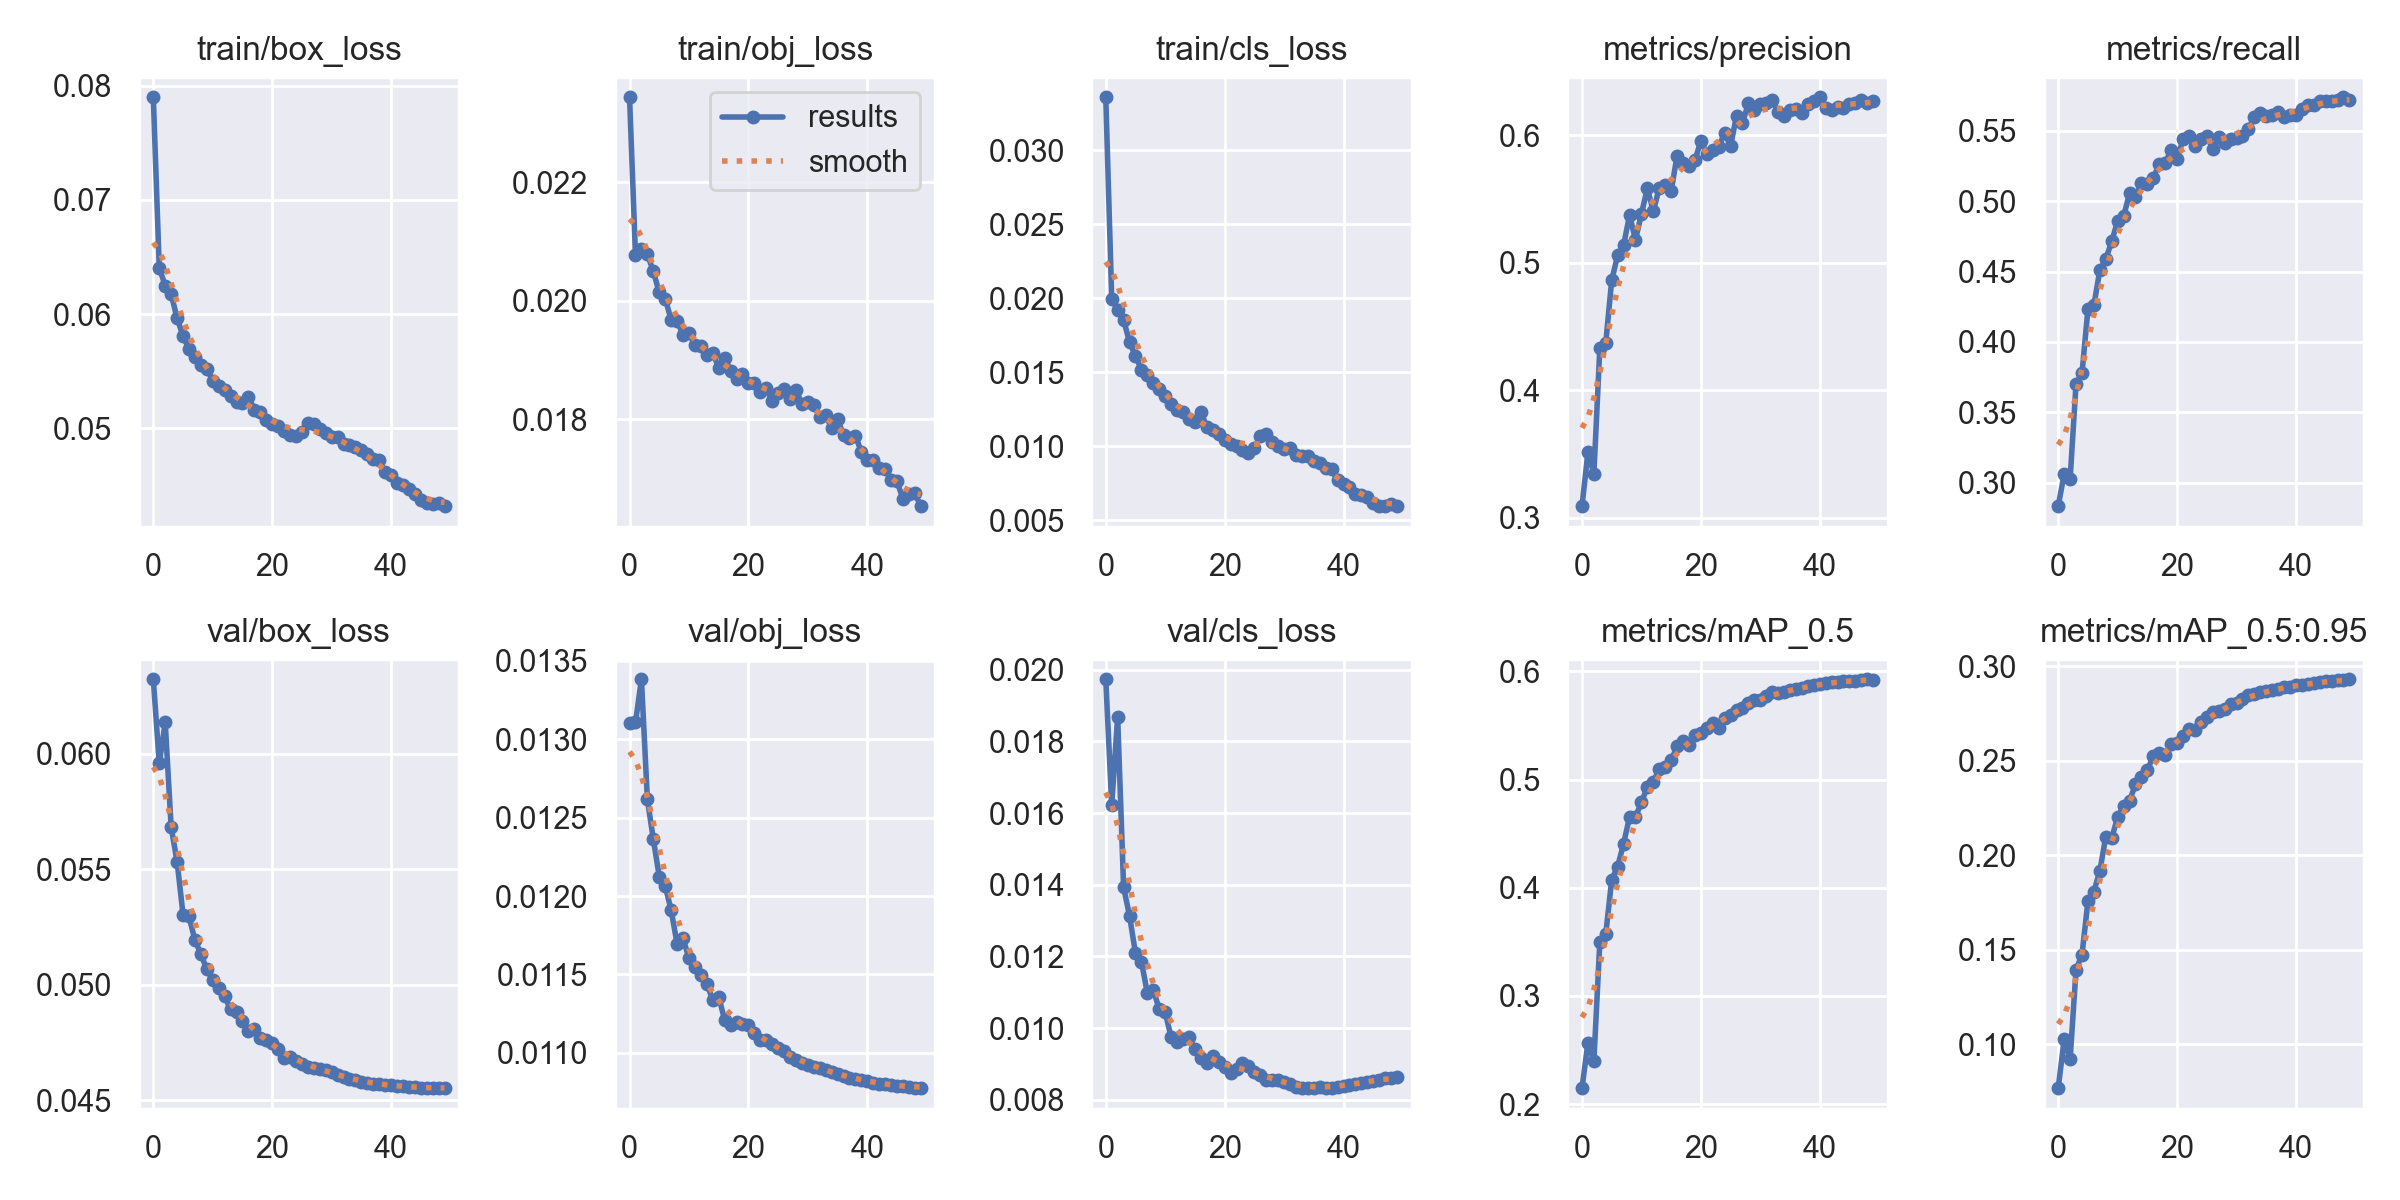


confusion_matrix.png


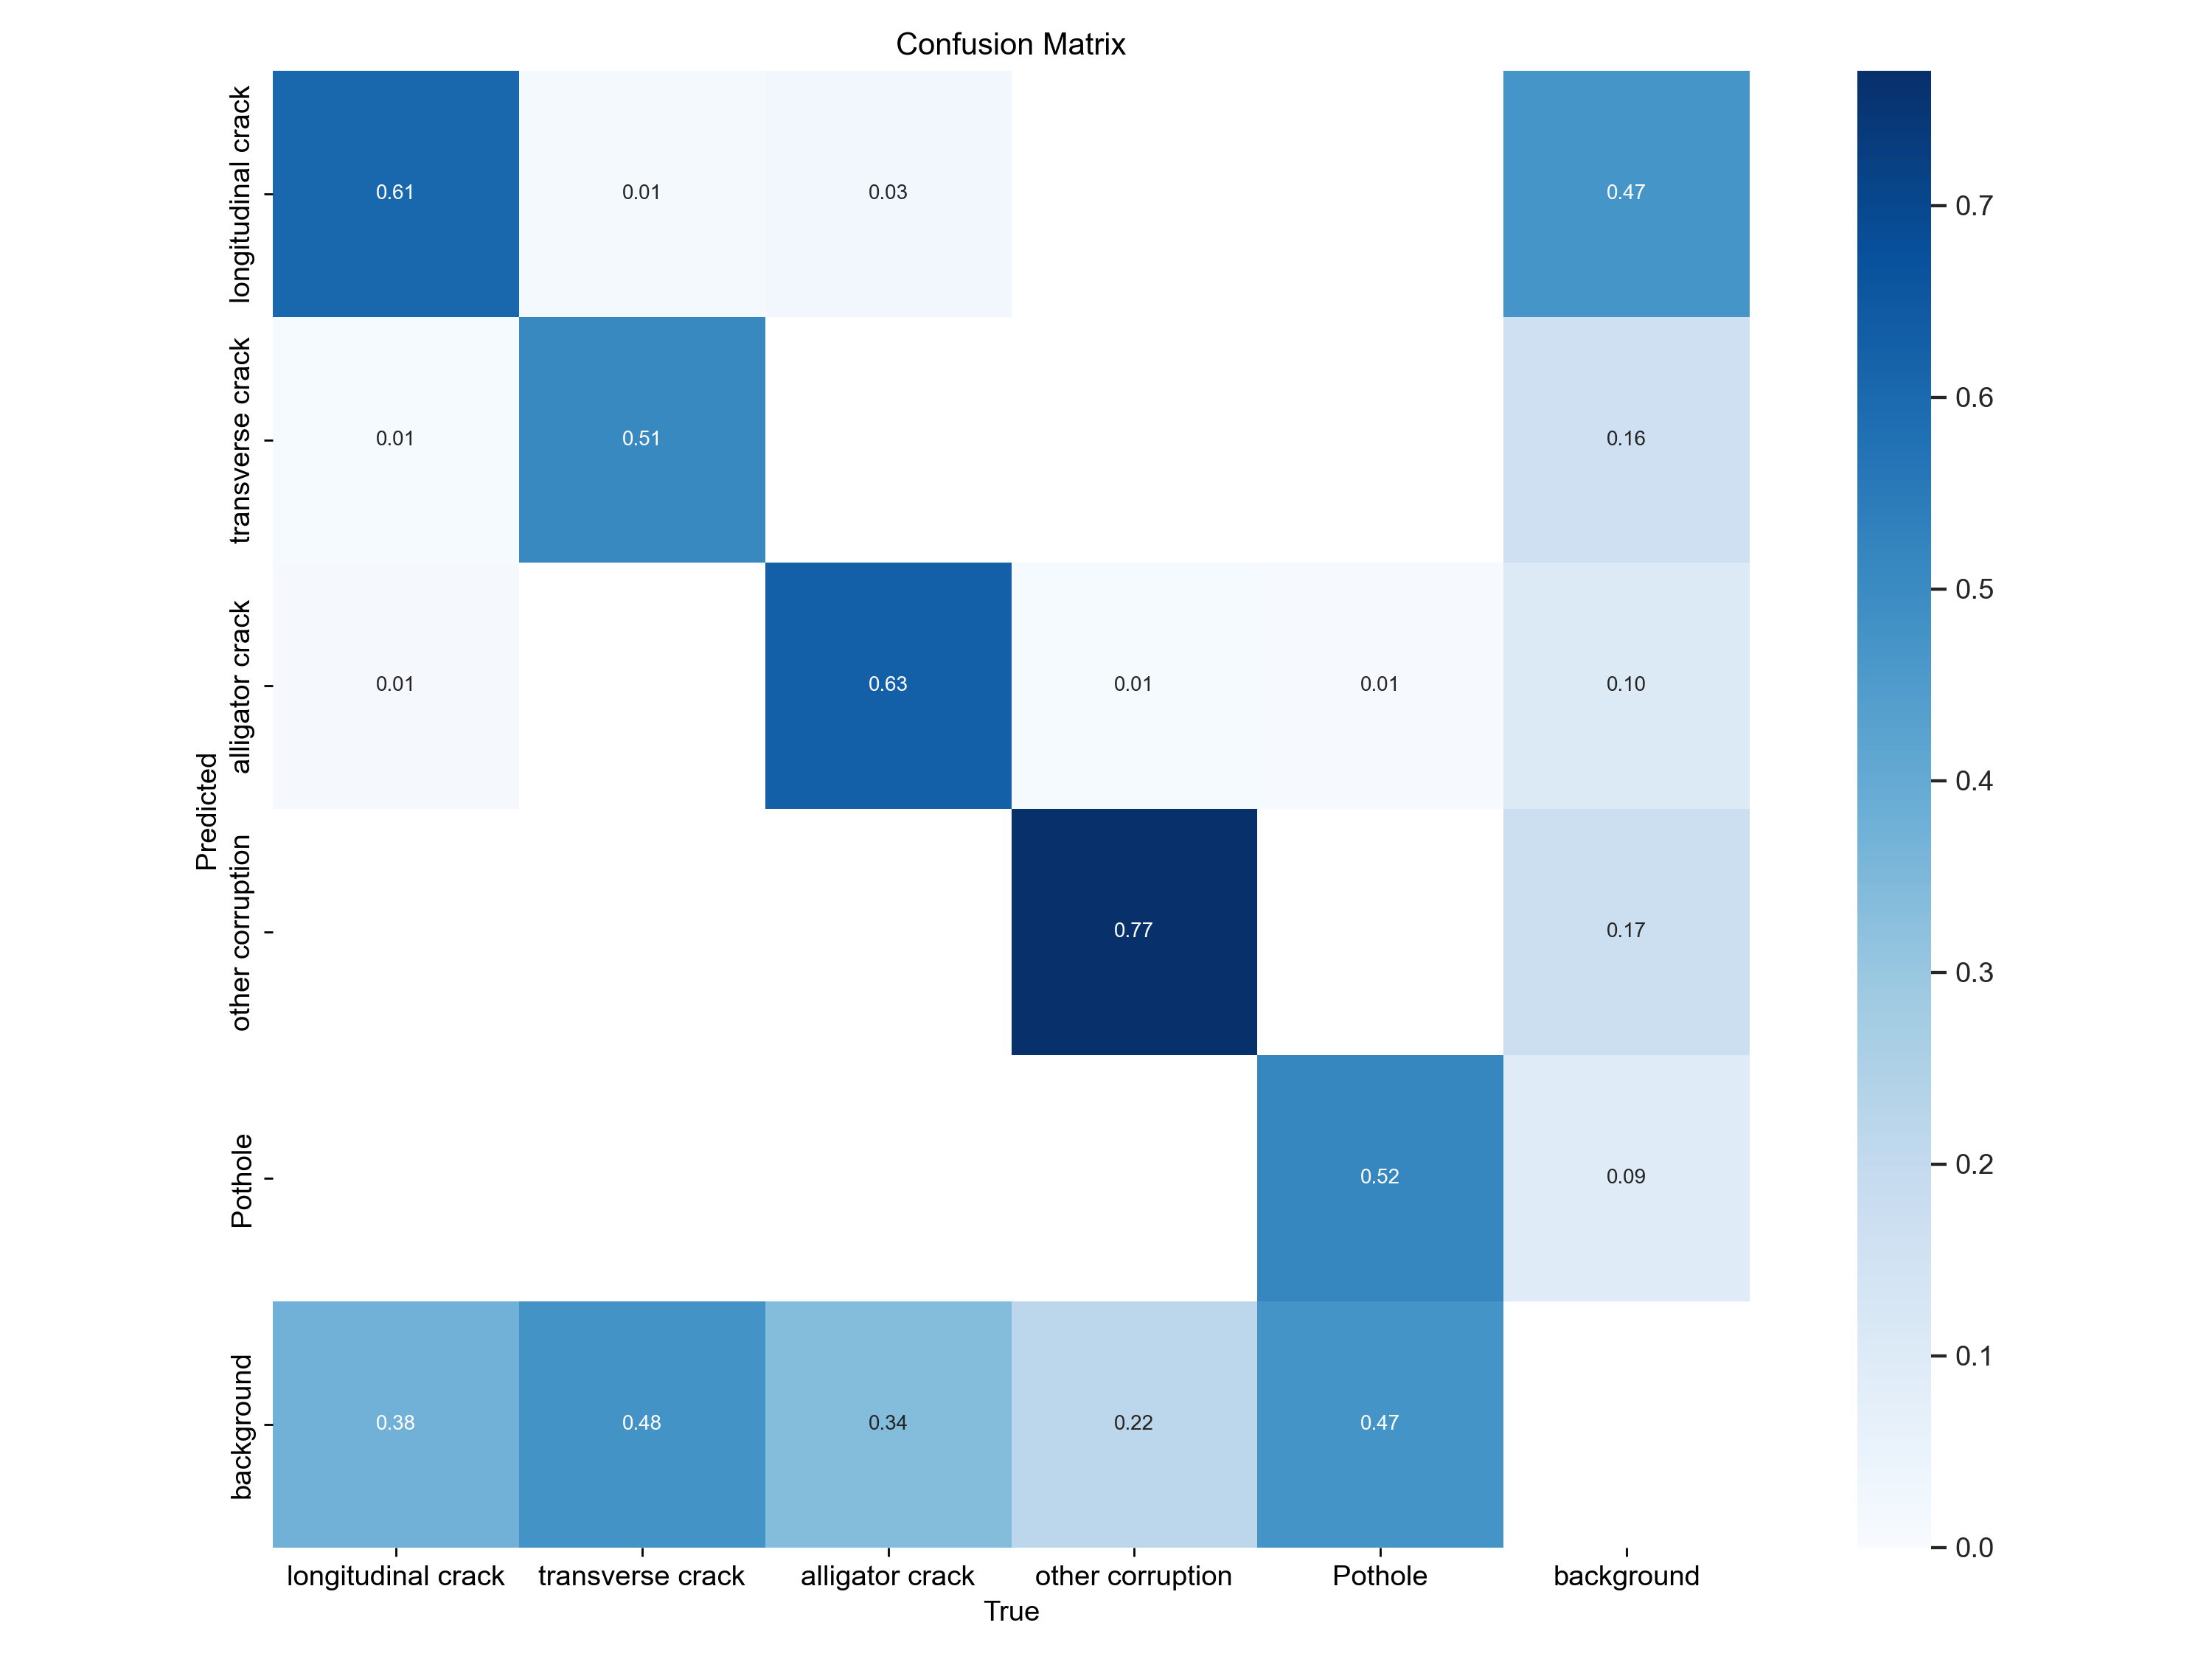


PR_curve.png


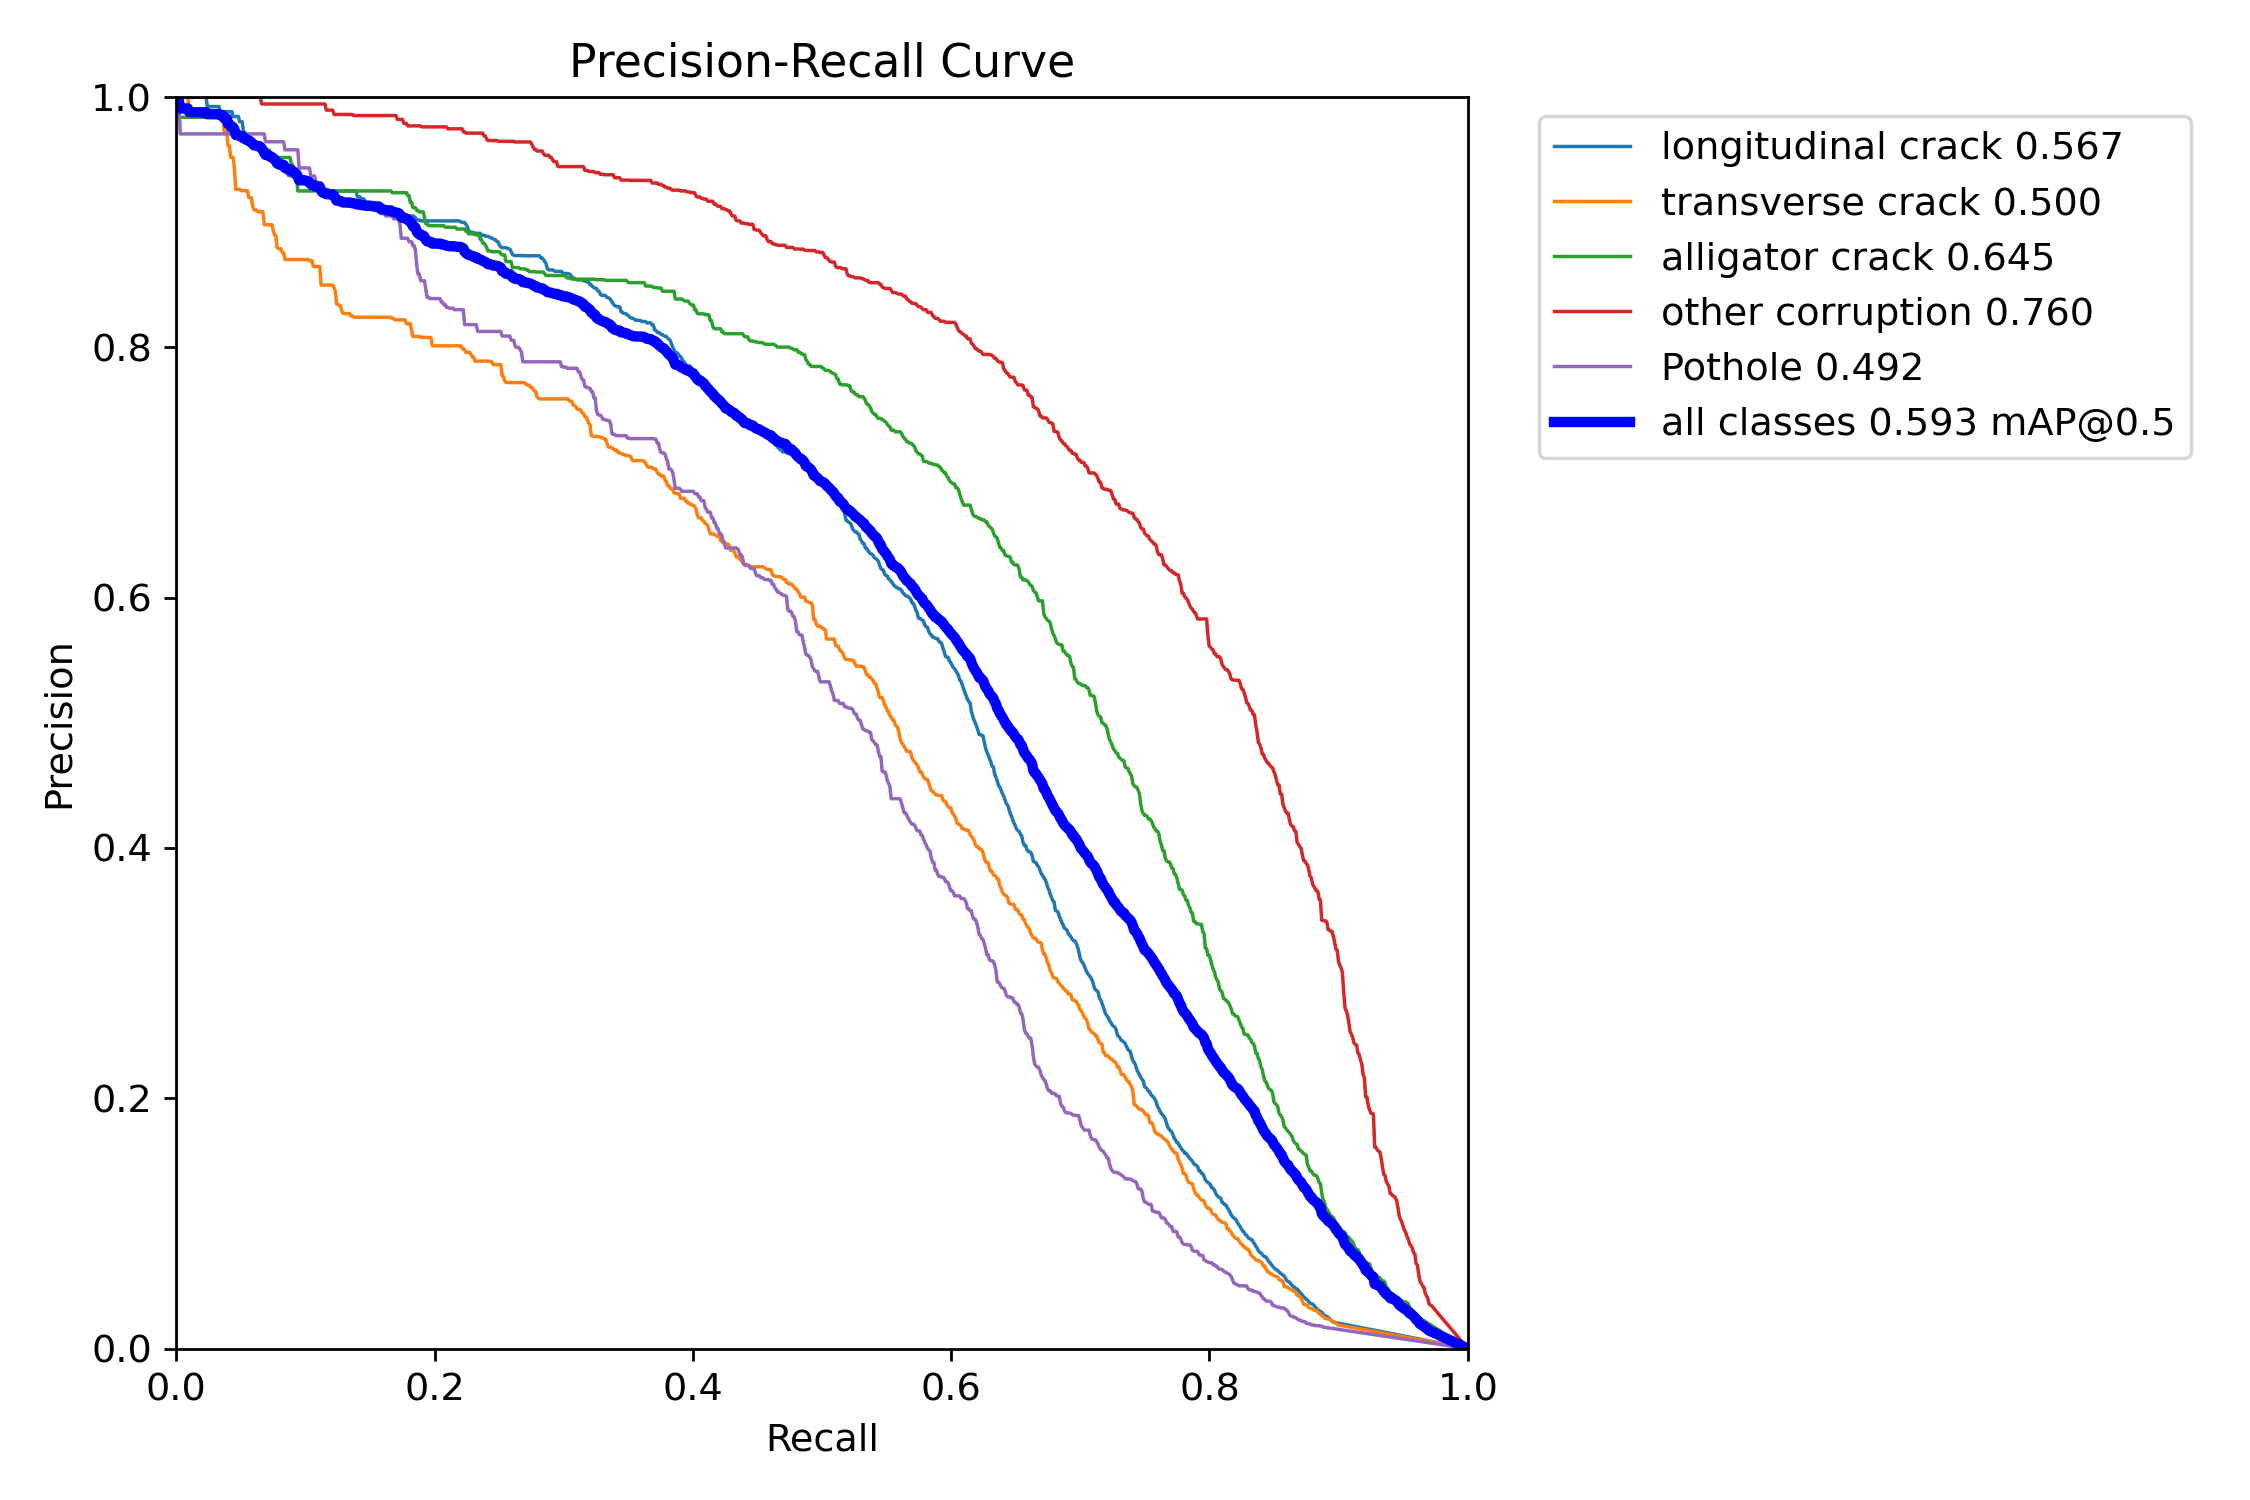


F1_curve.png


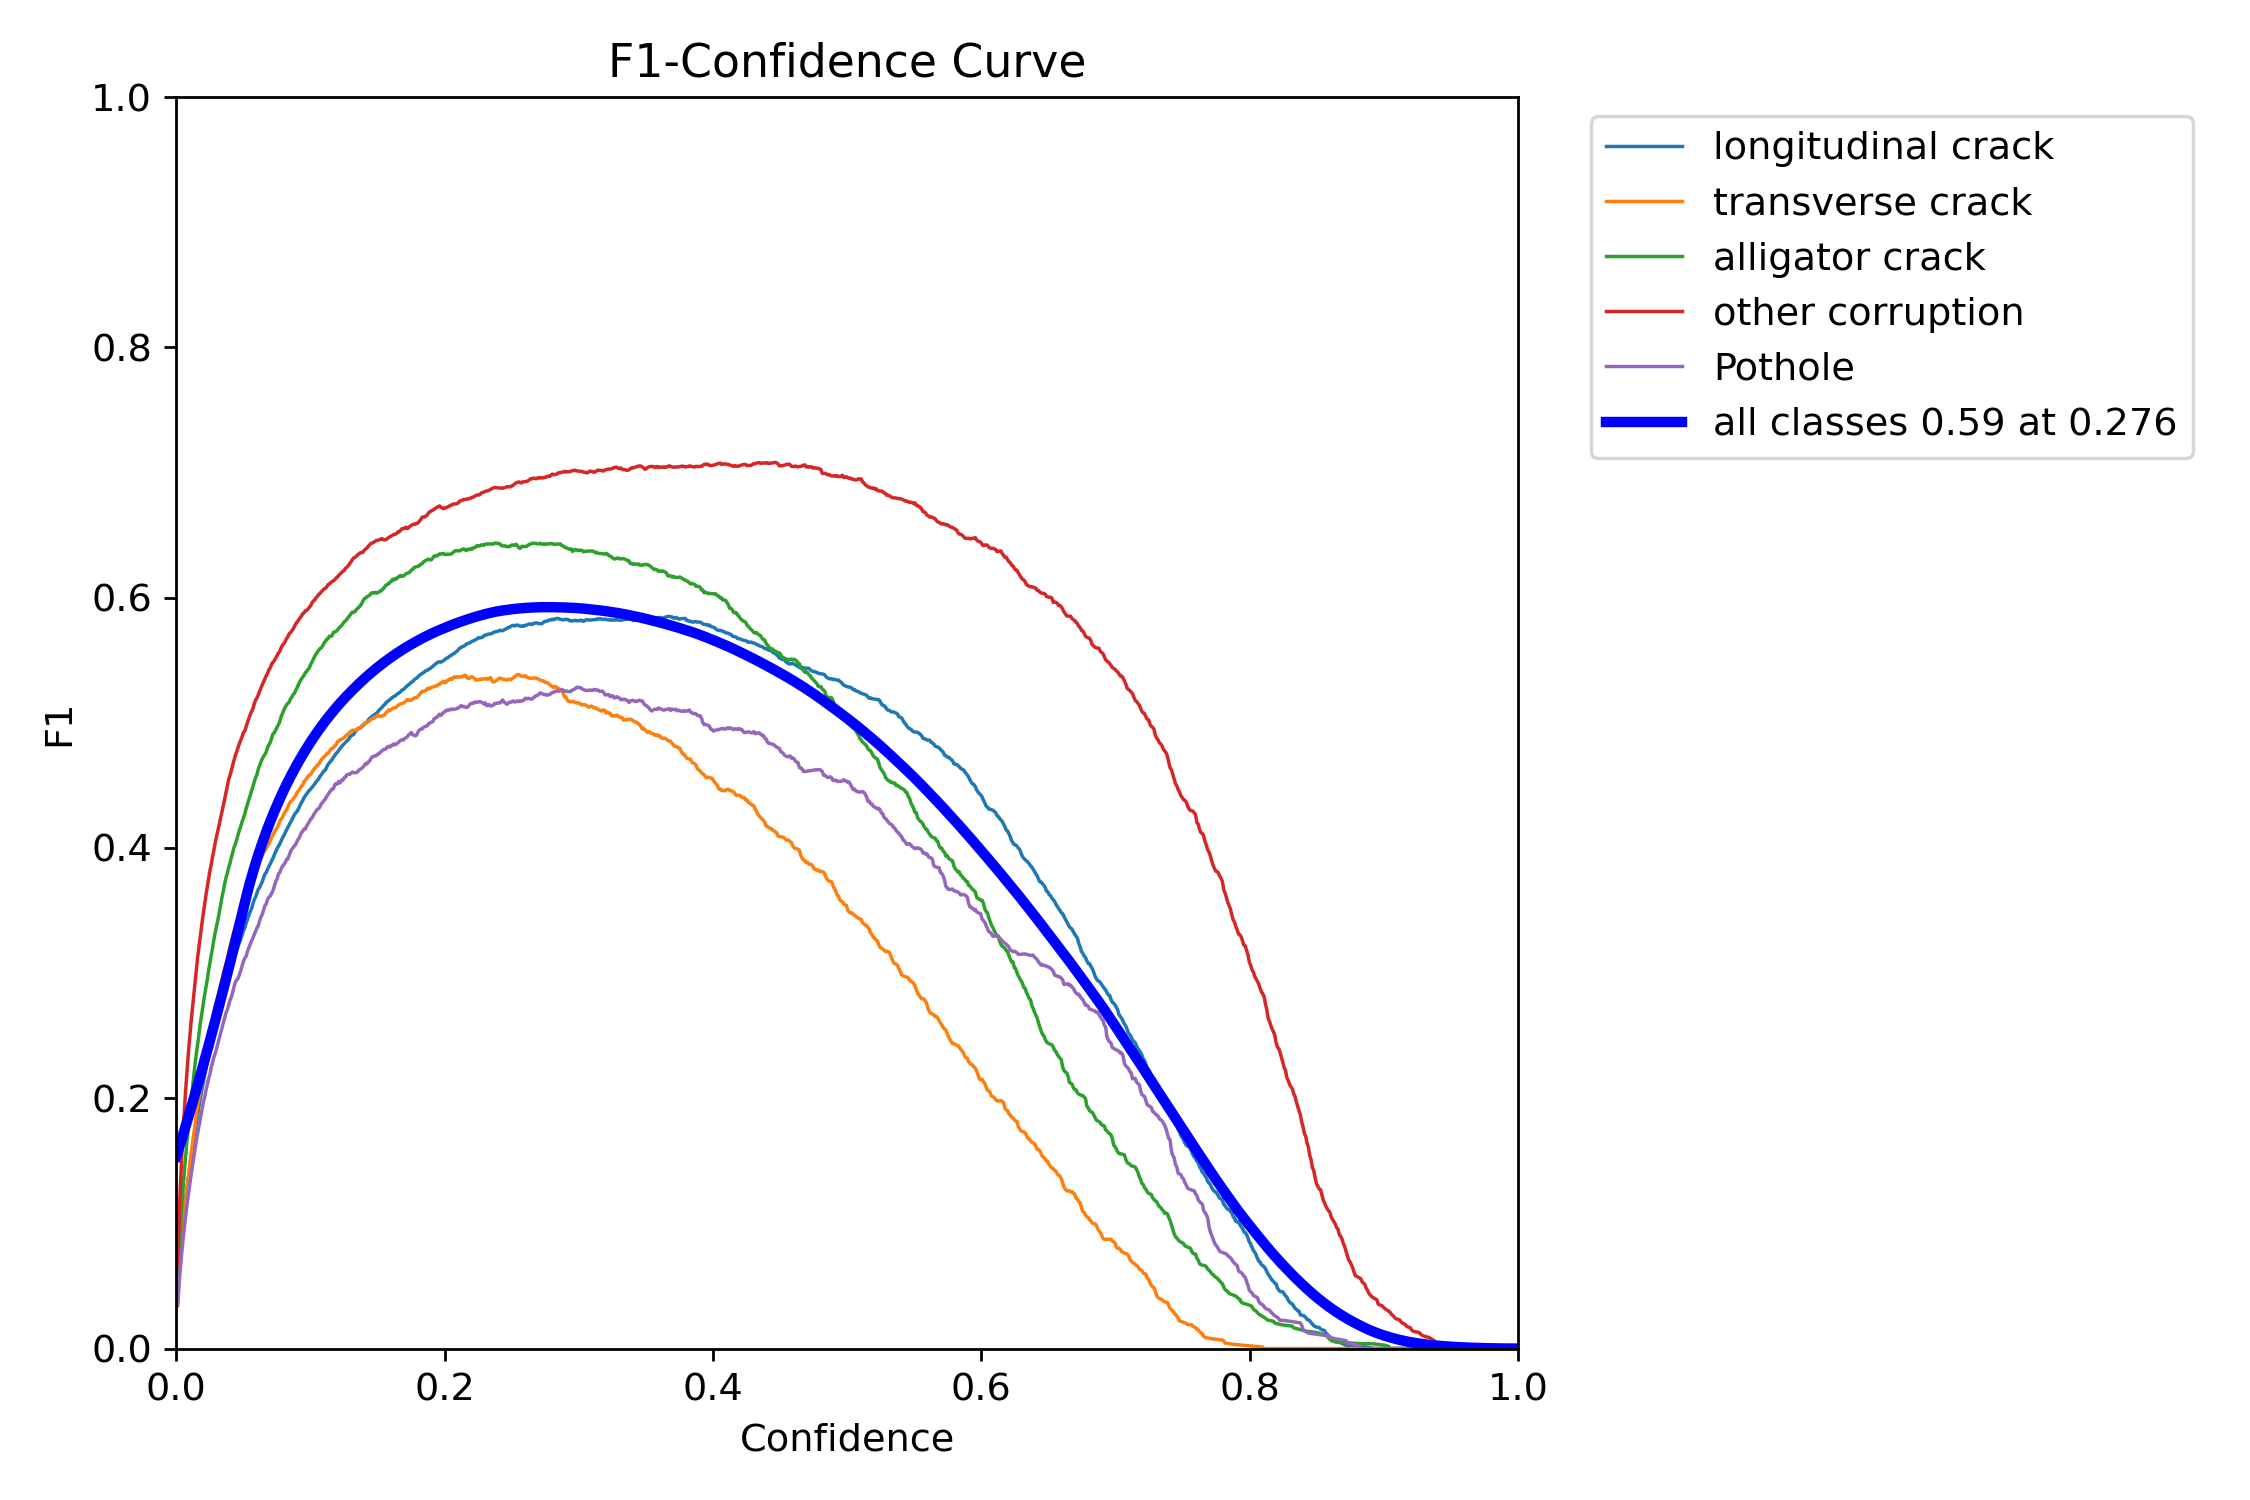


P_curve.png


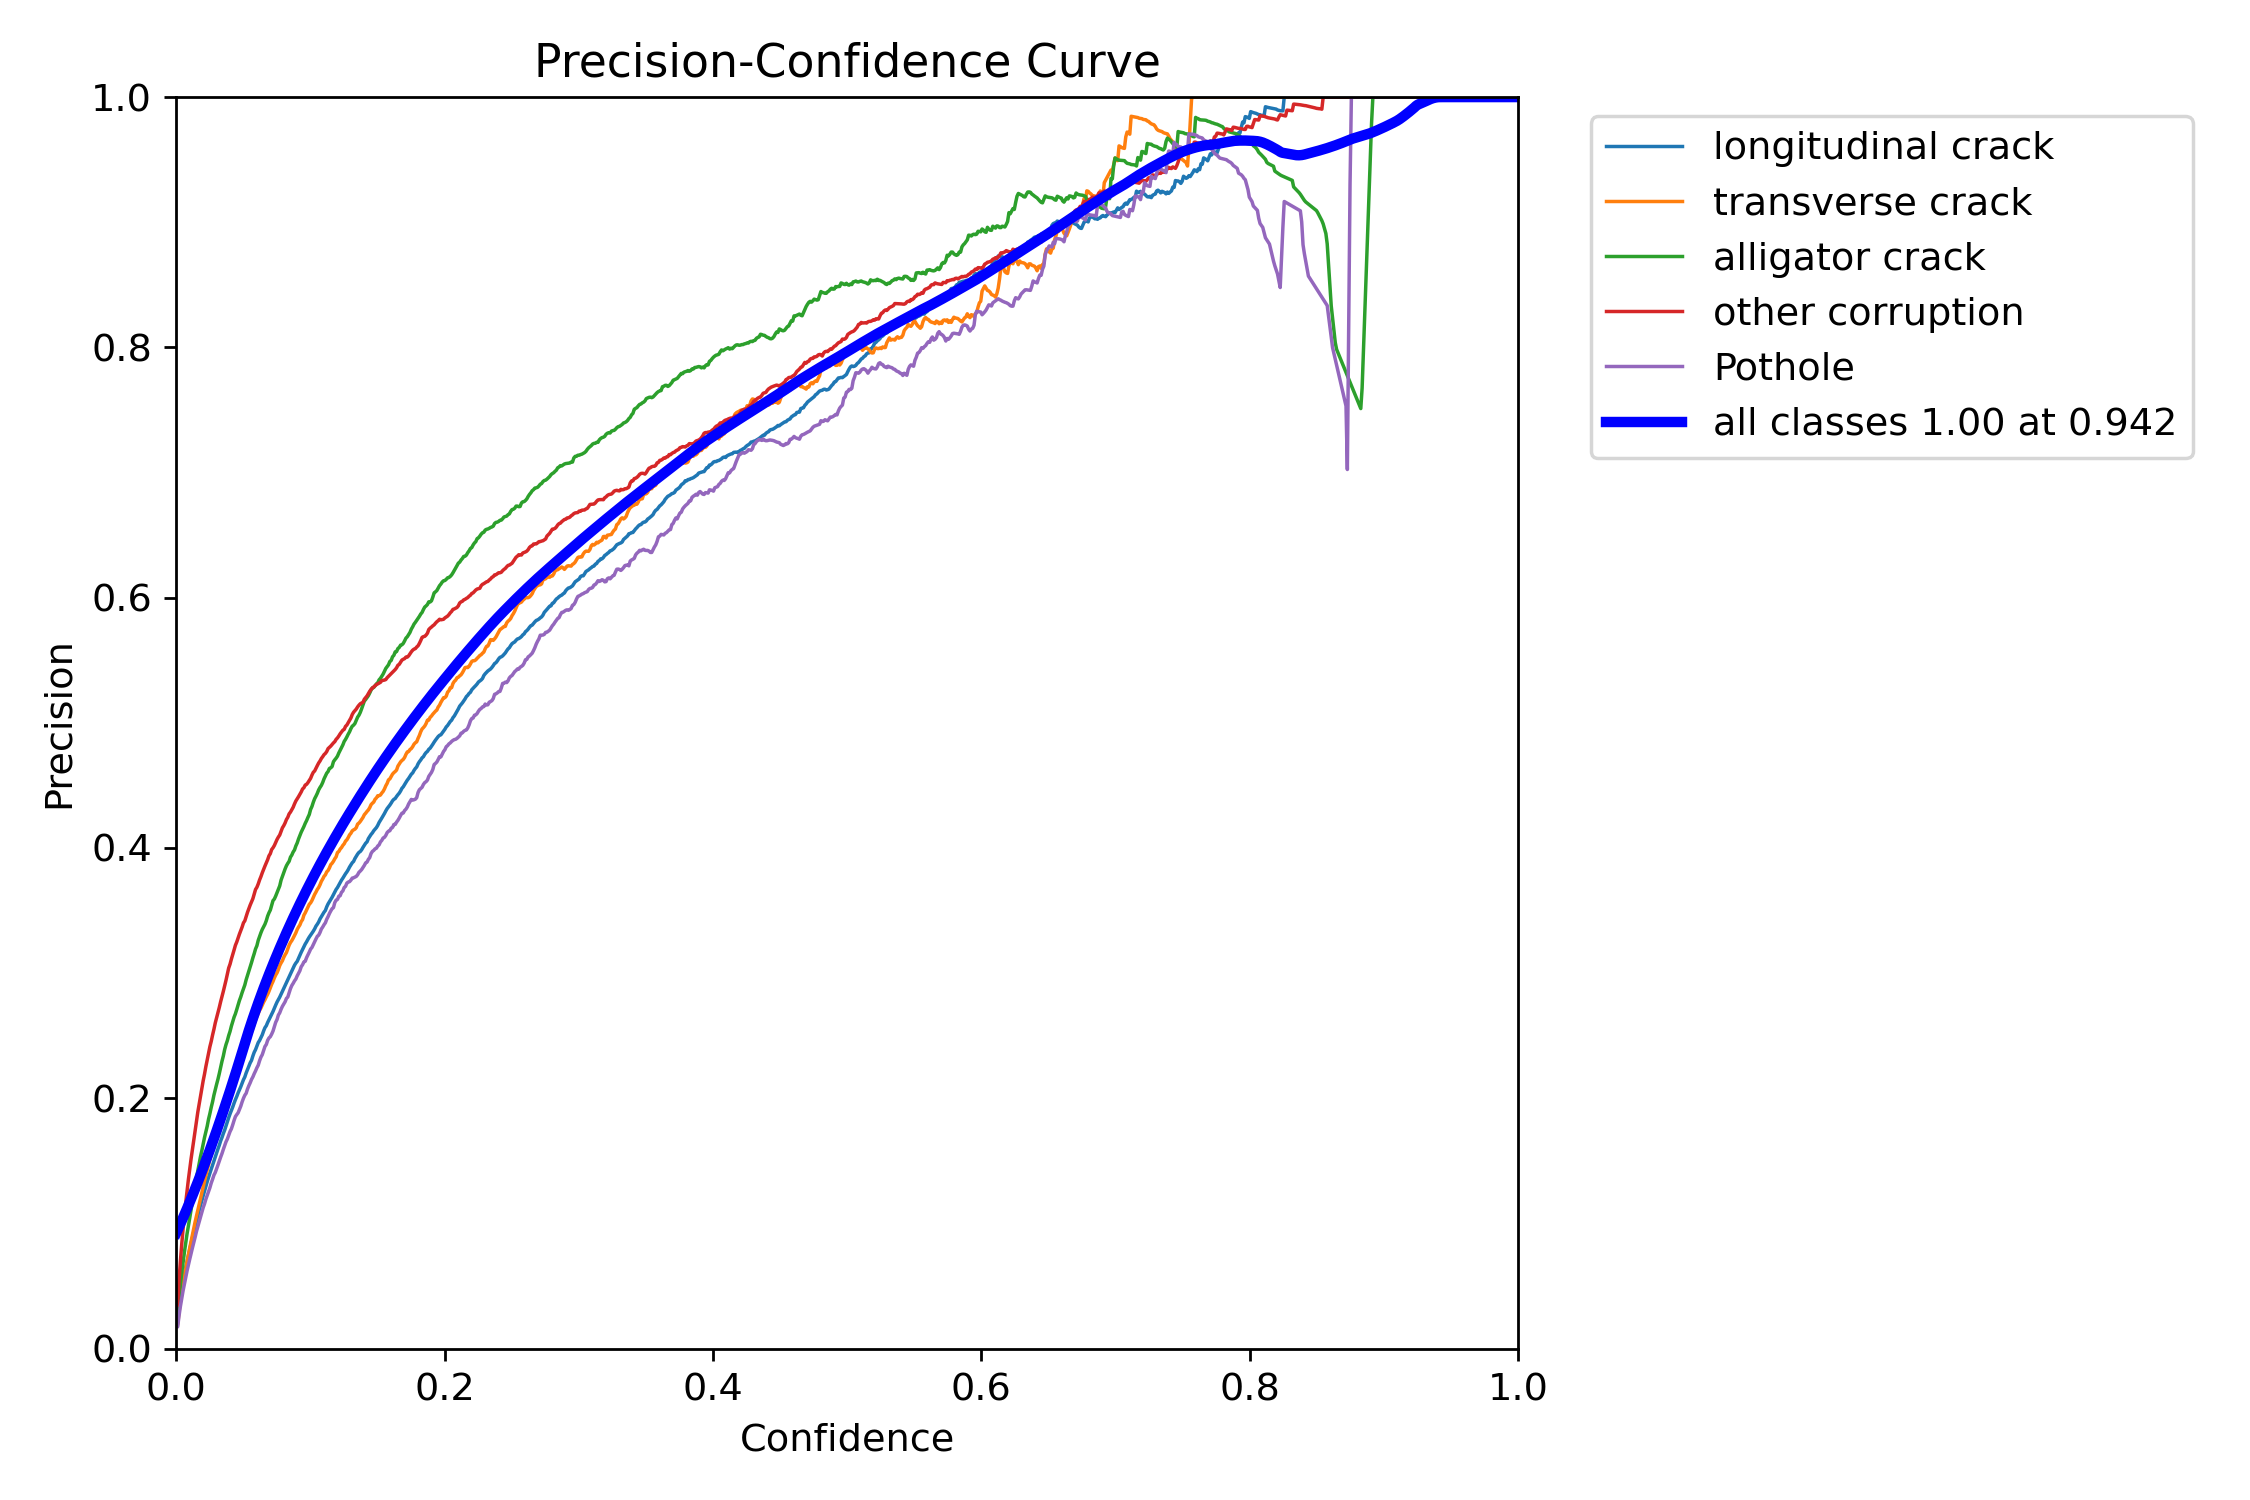


R_curve.png


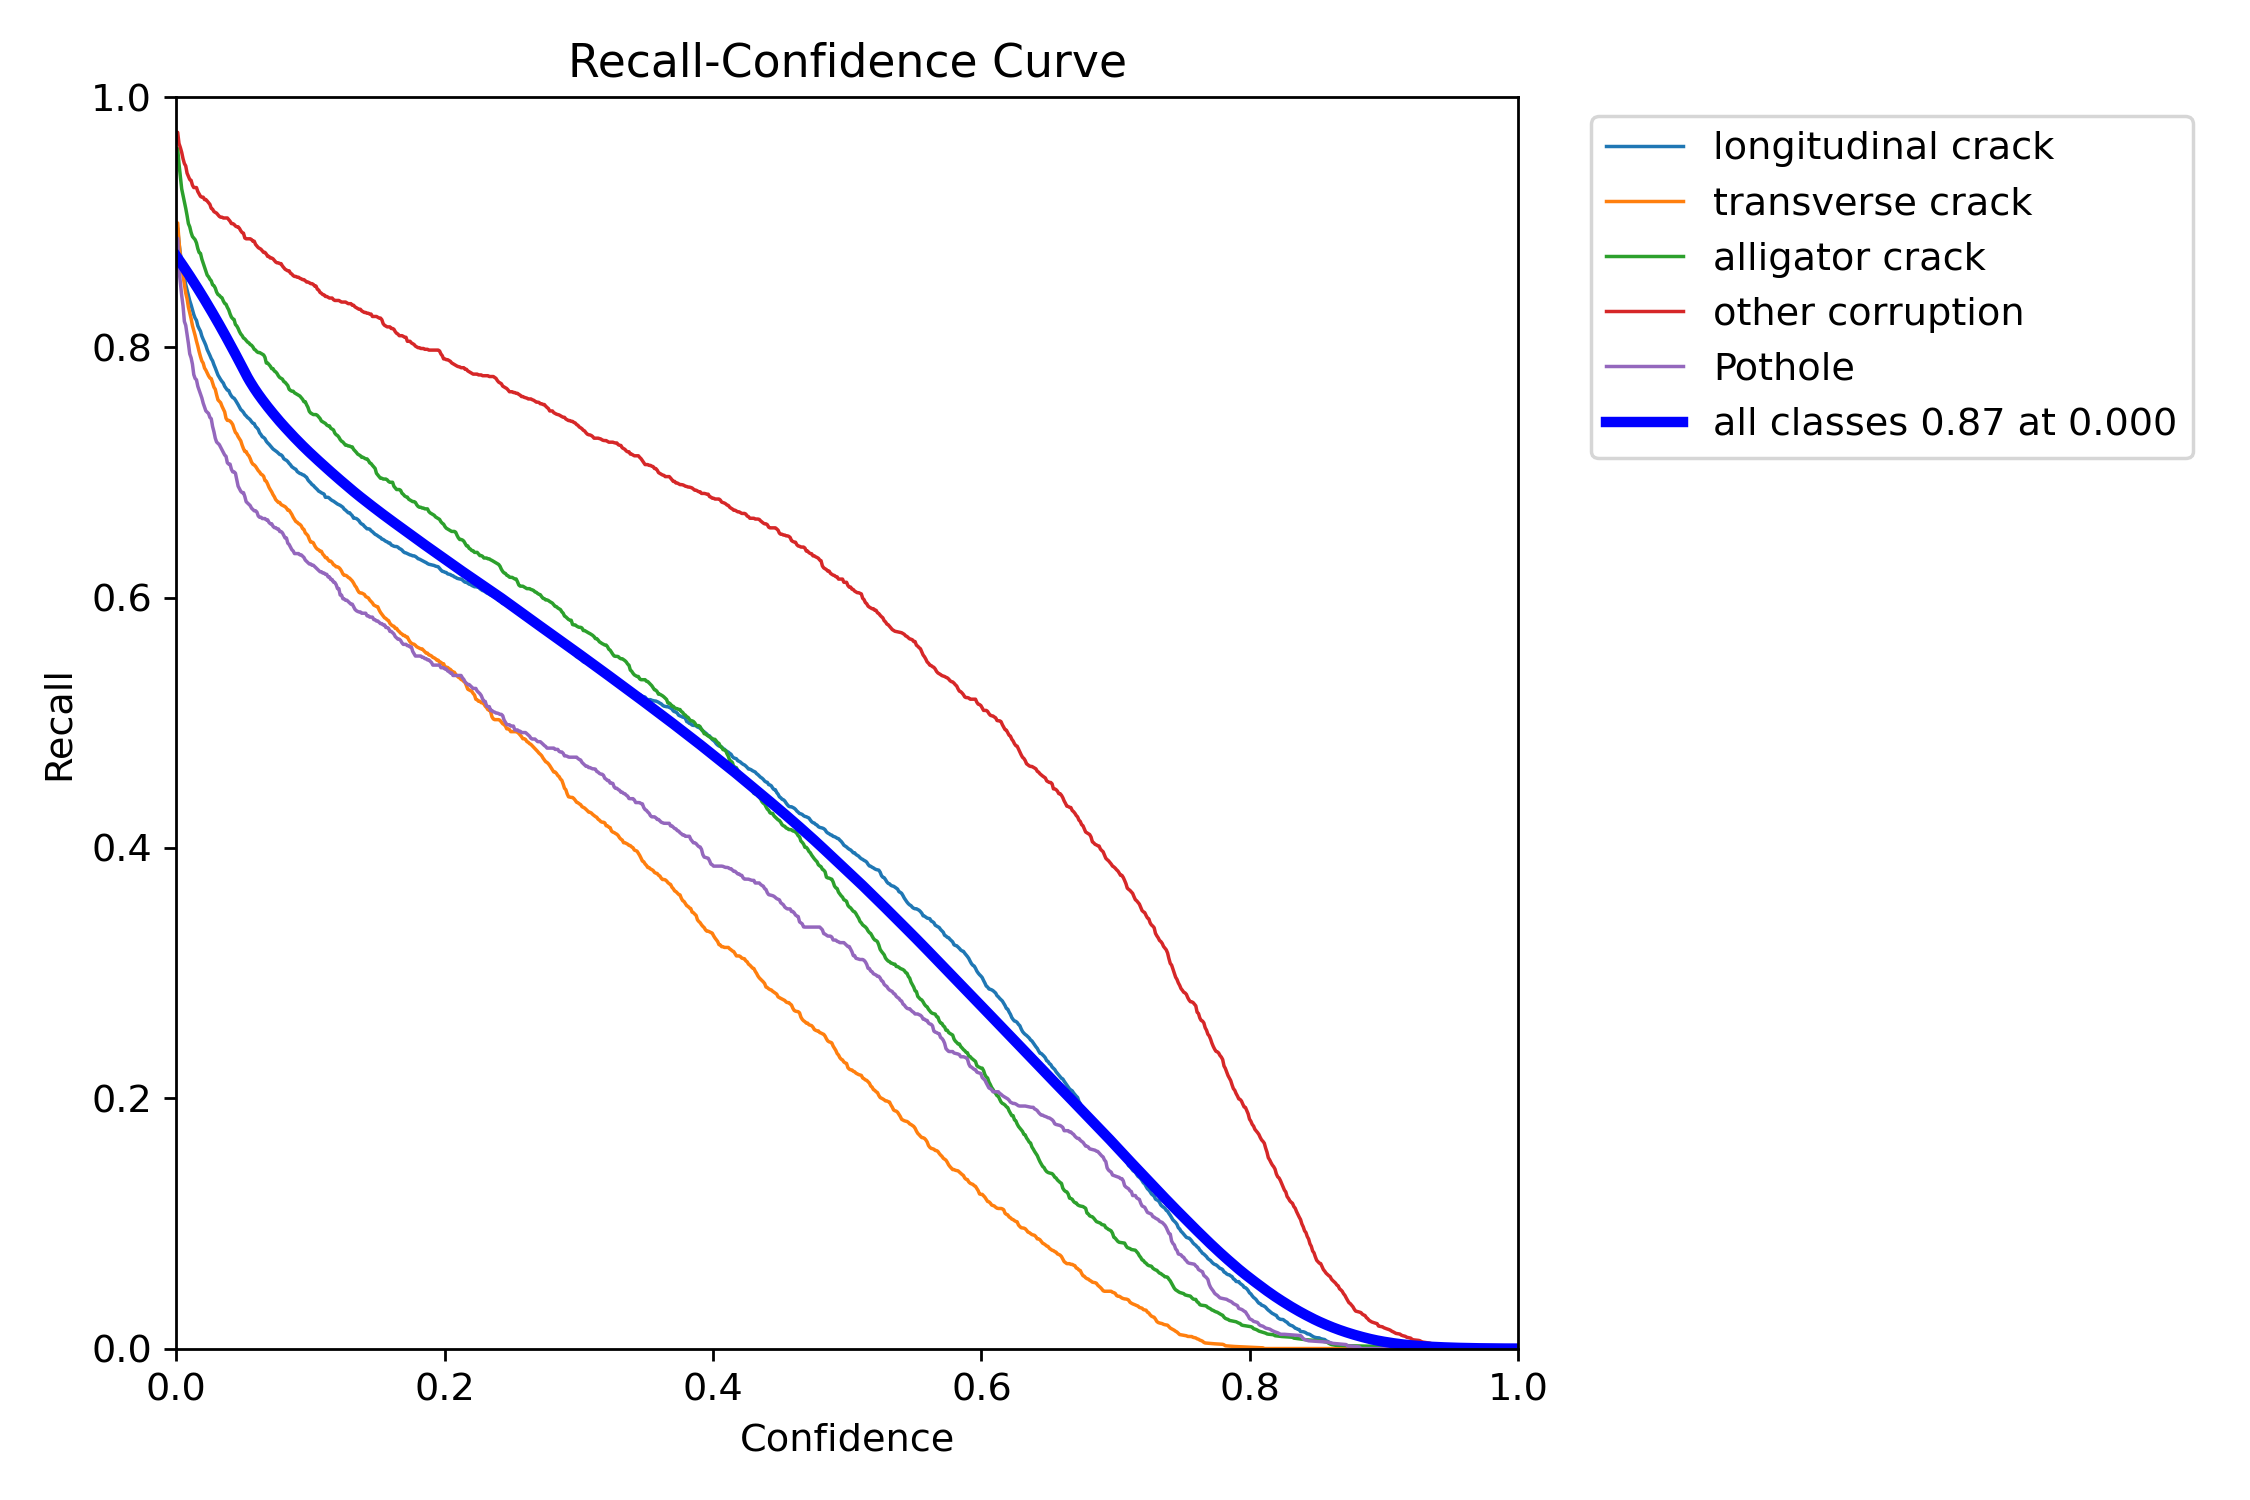


labels.jpg


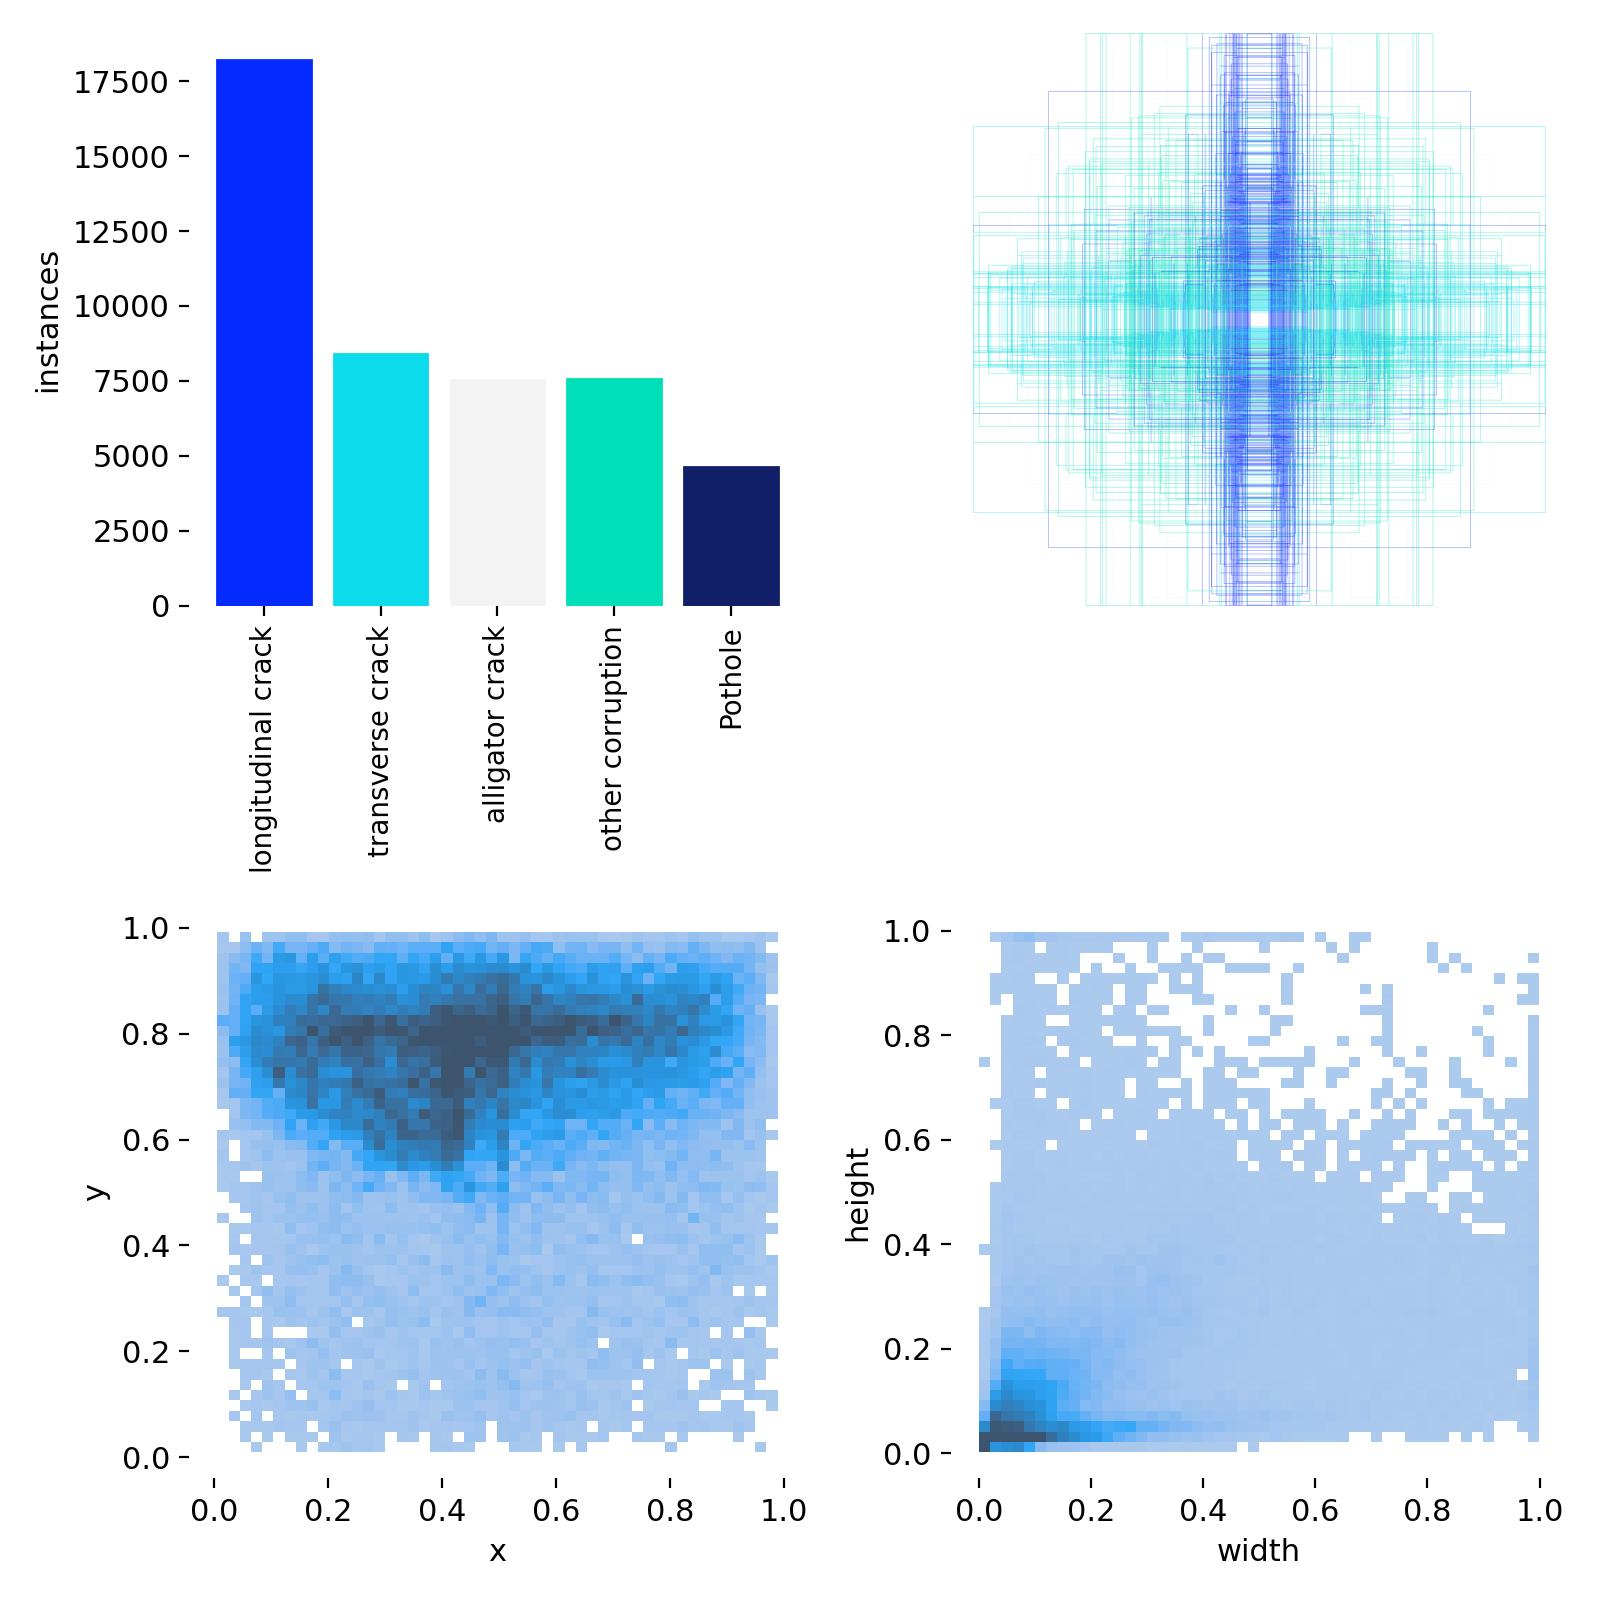


labels_correlogram.jpg


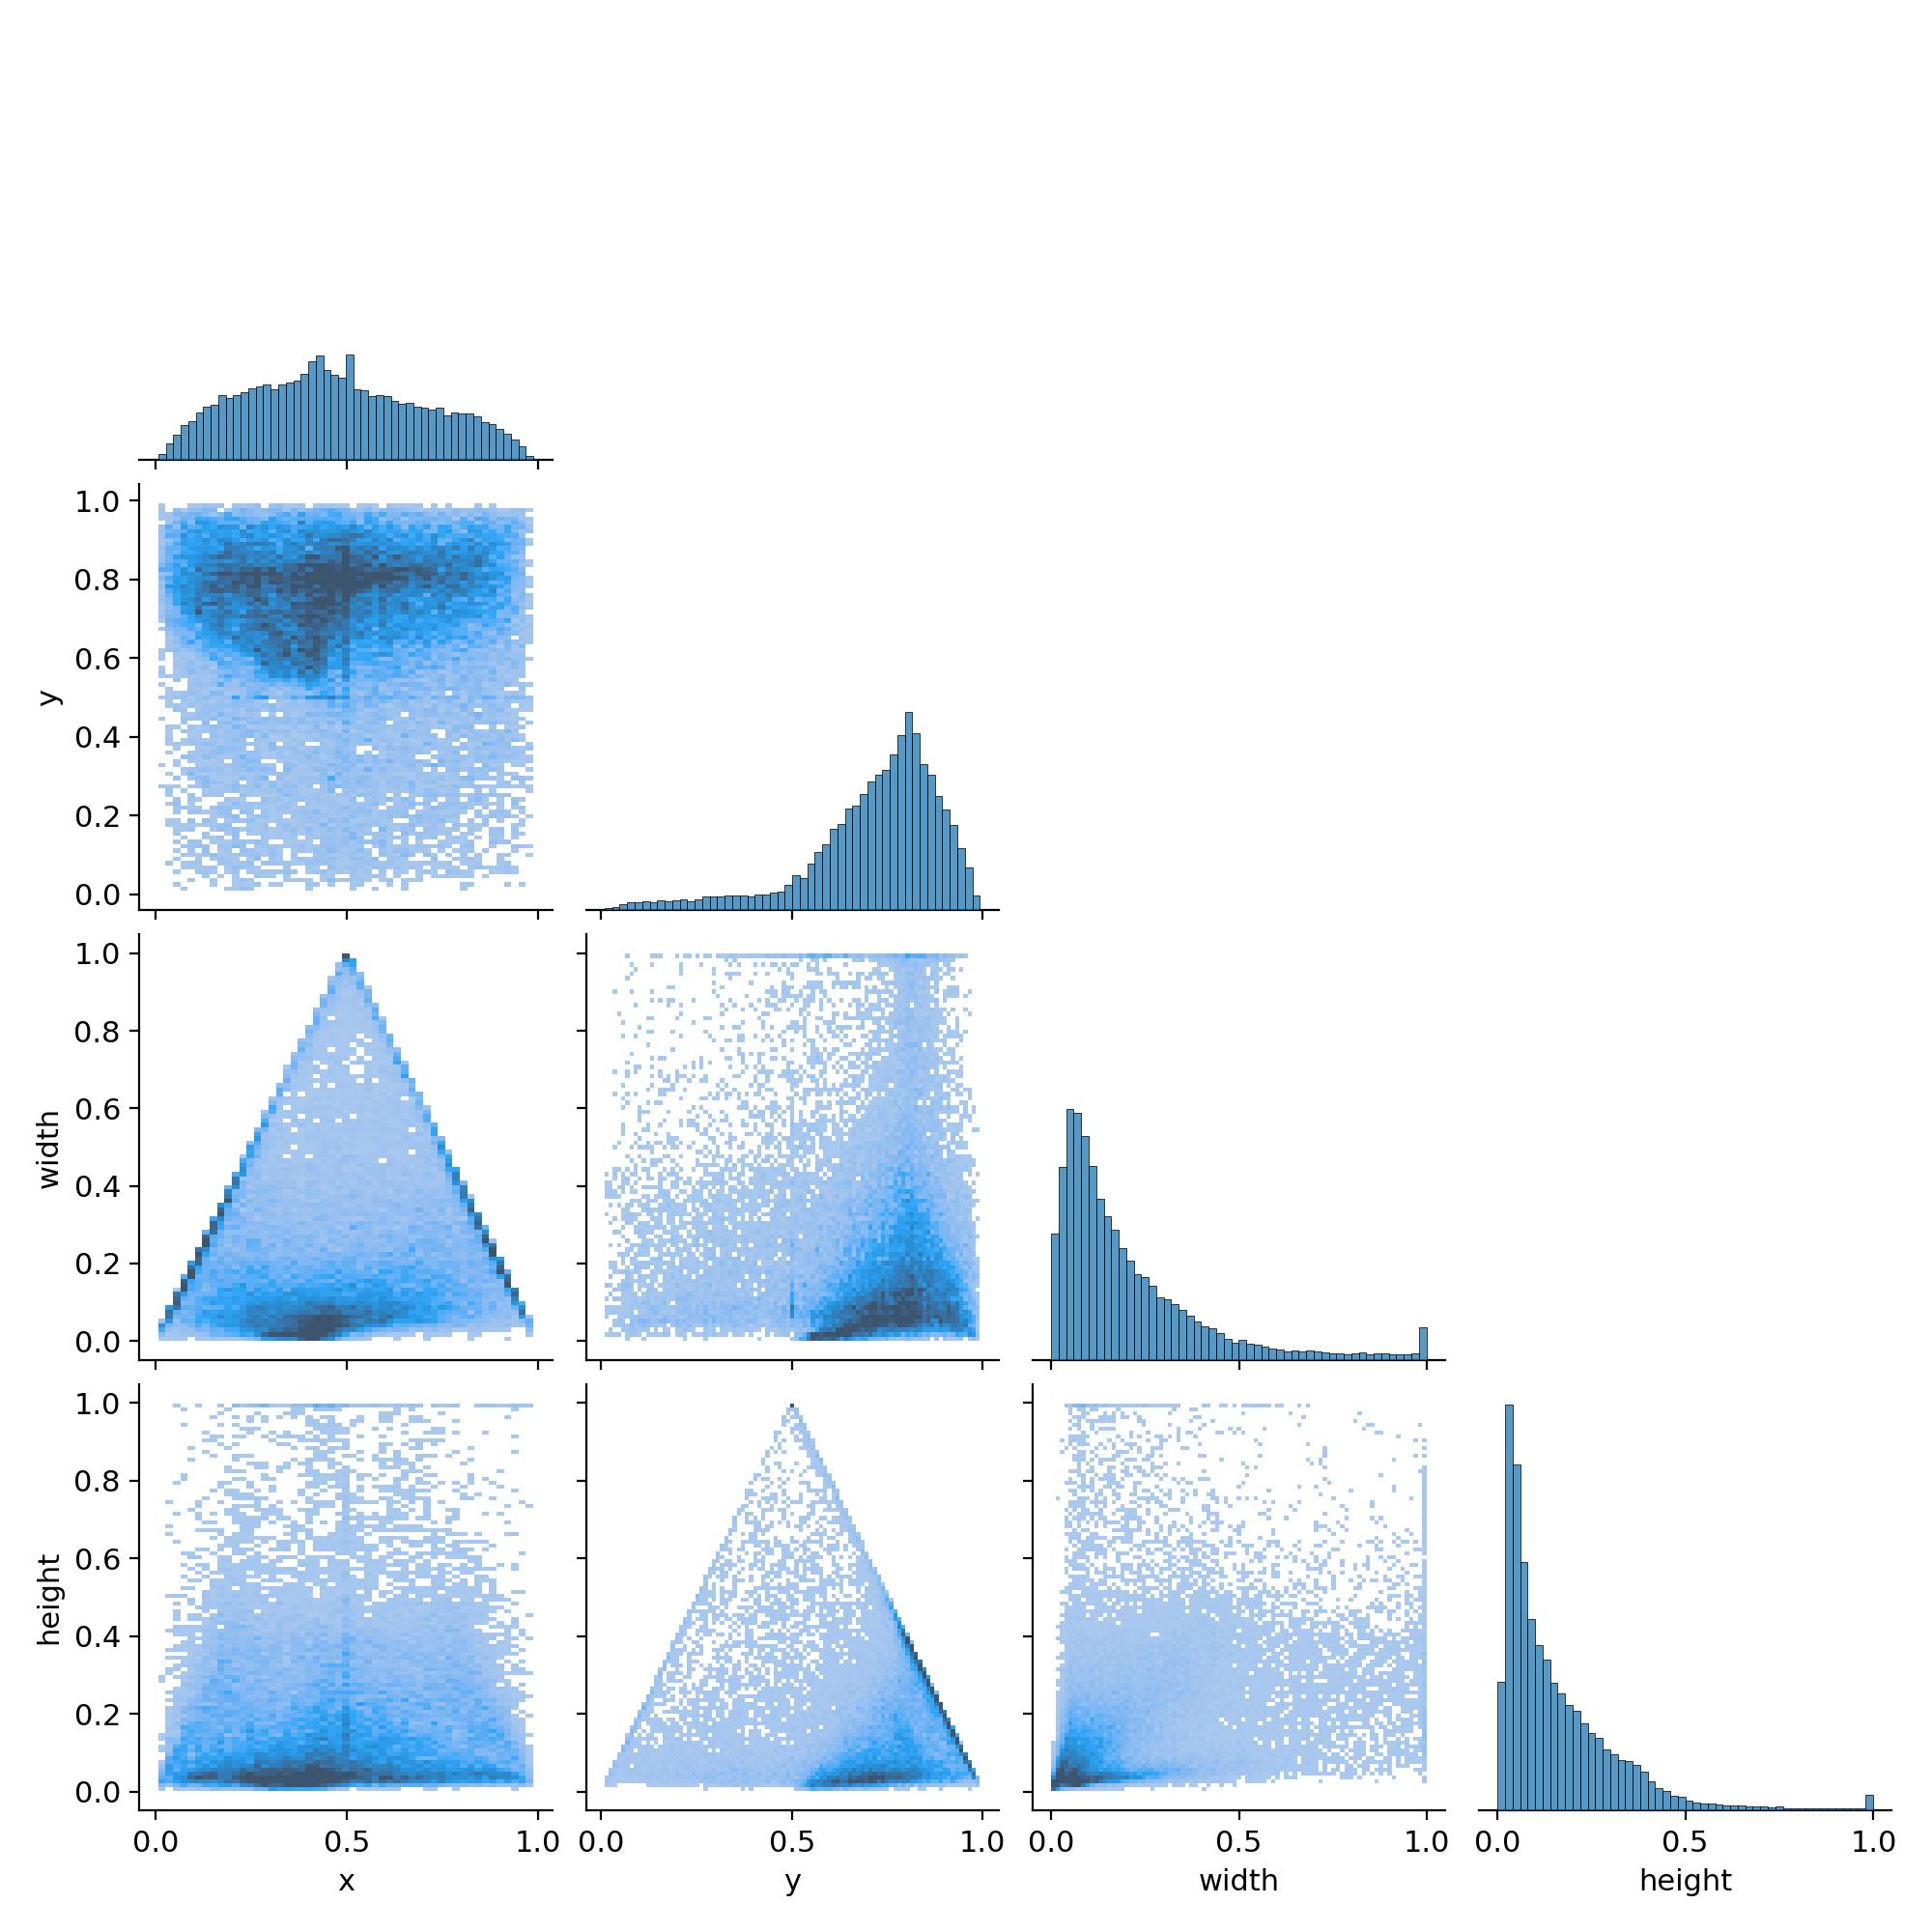

In [71]:
from IPython.display import Image, display

training_plot_files = [
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
    "labels.jpg",
    "labels_correlogram.jpg"
]

for filename in training_plot_files:
    file_path = RUN_DIRECTORY / filename

    if file_path.exists():
        print(f"\n{filename}")

        display(
            Image(
                filename=str(file_path)
            )
        )


val_batch0_labels.jpg


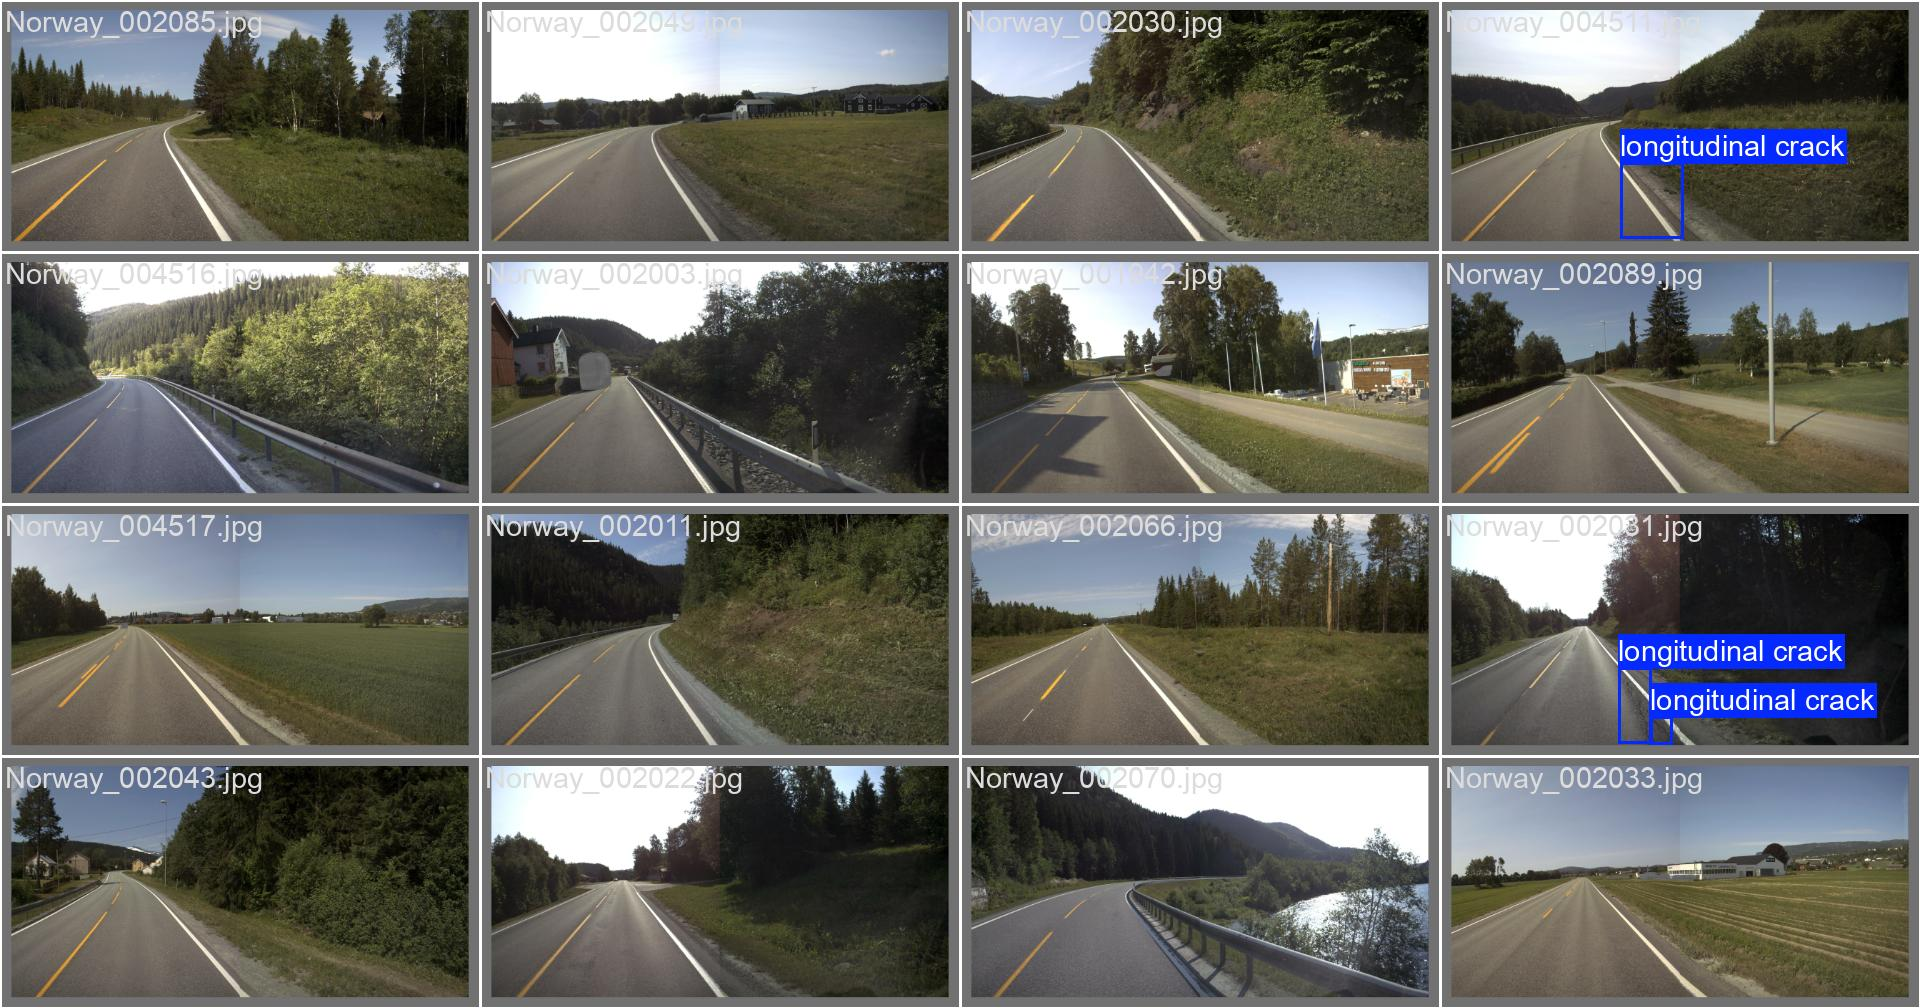


val_batch0_pred.jpg


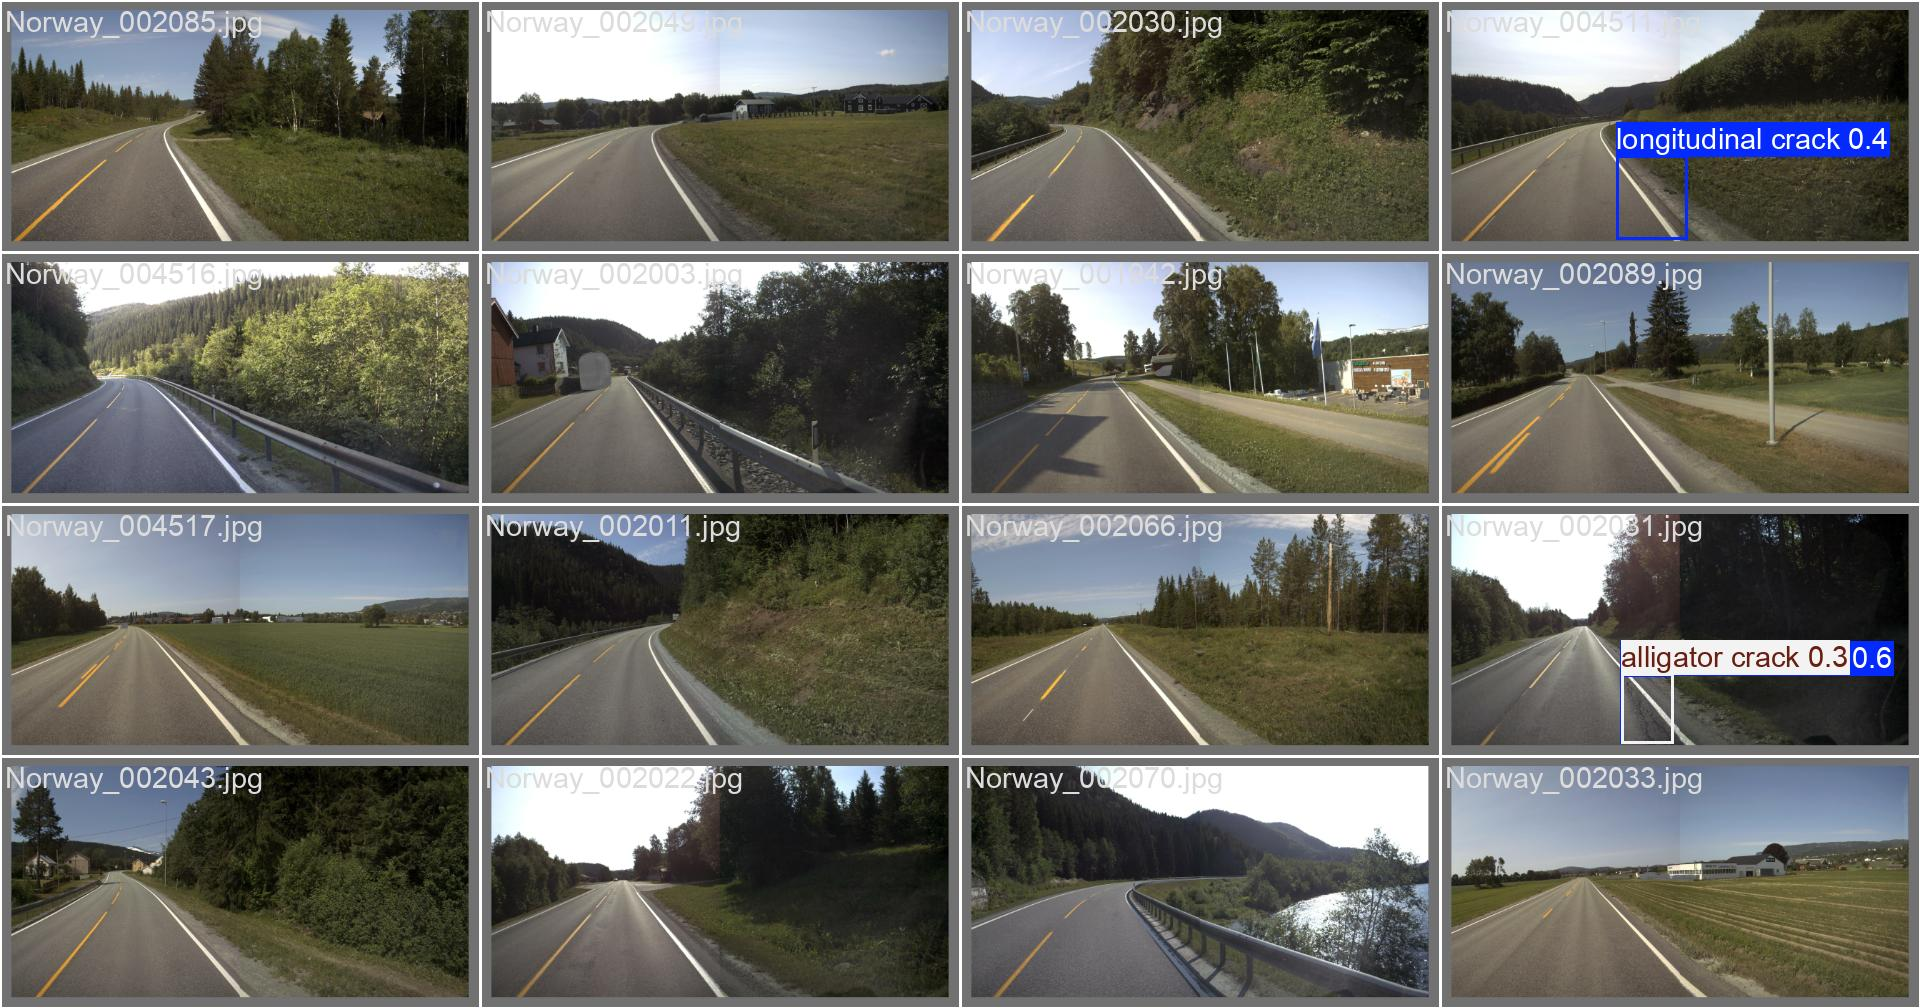


val_batch1_labels.jpg


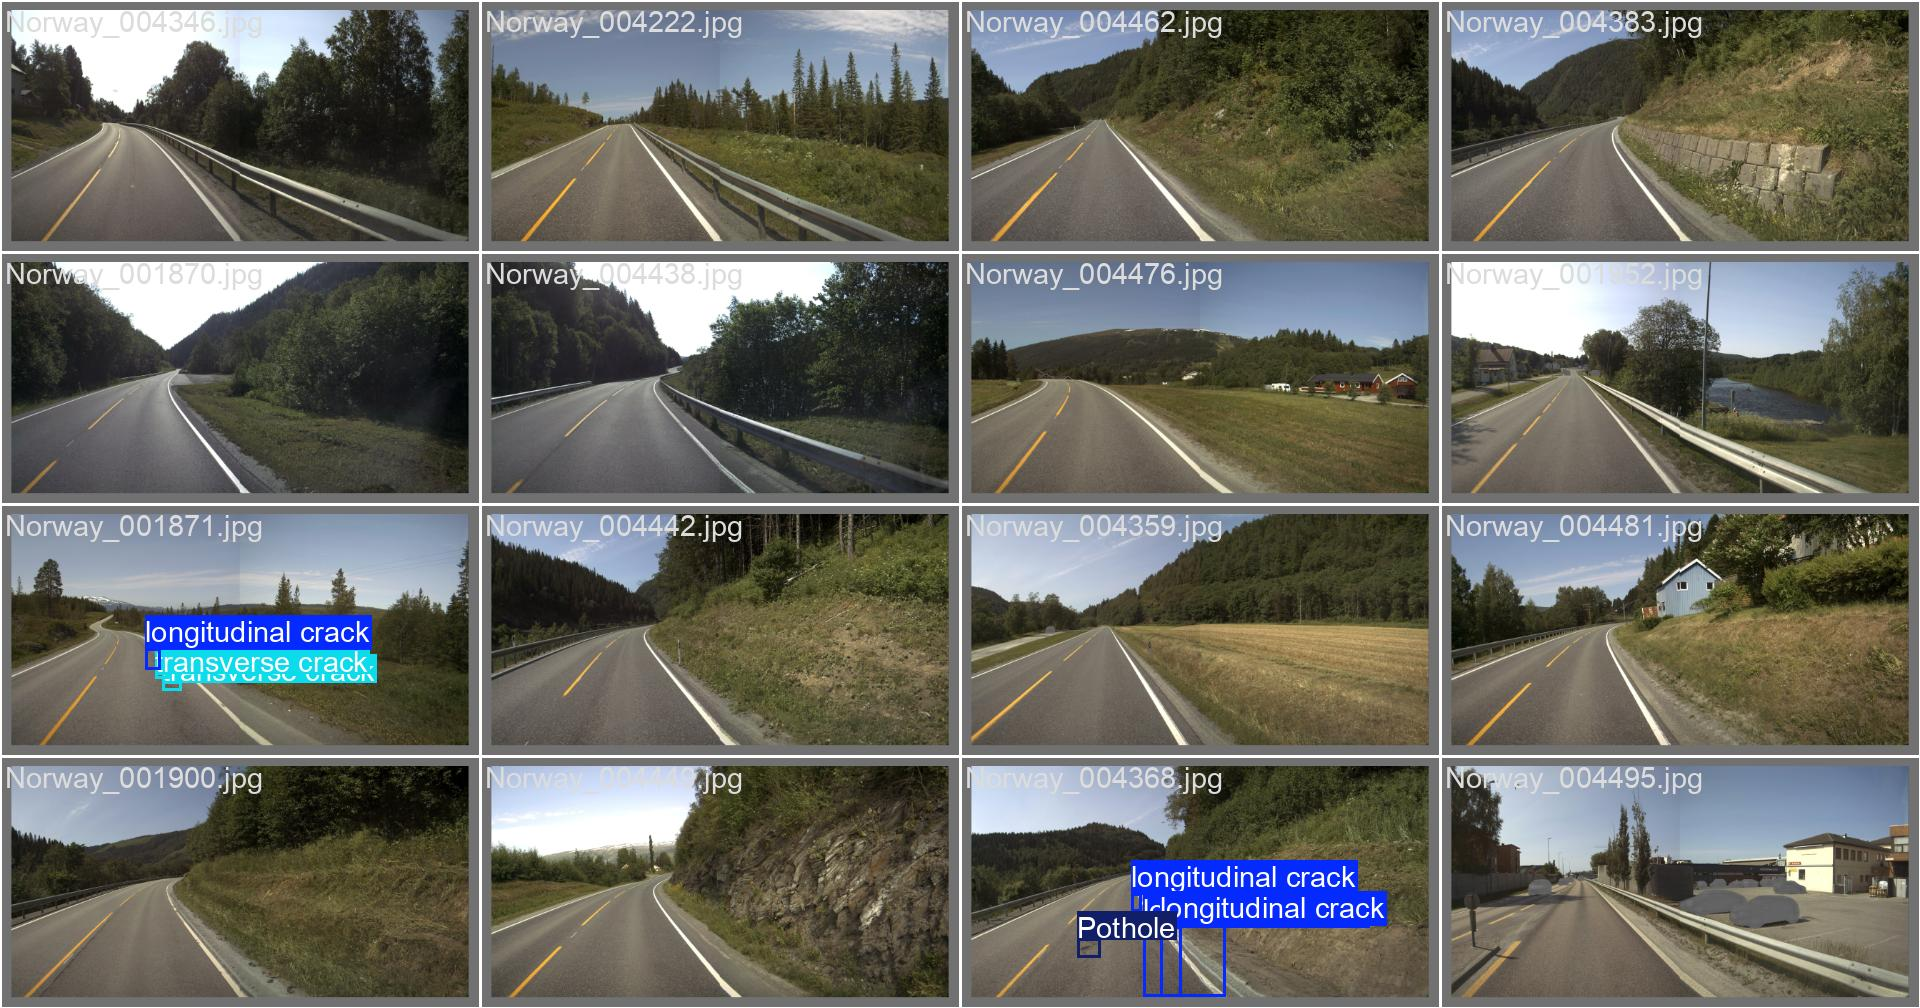


val_batch1_pred.jpg


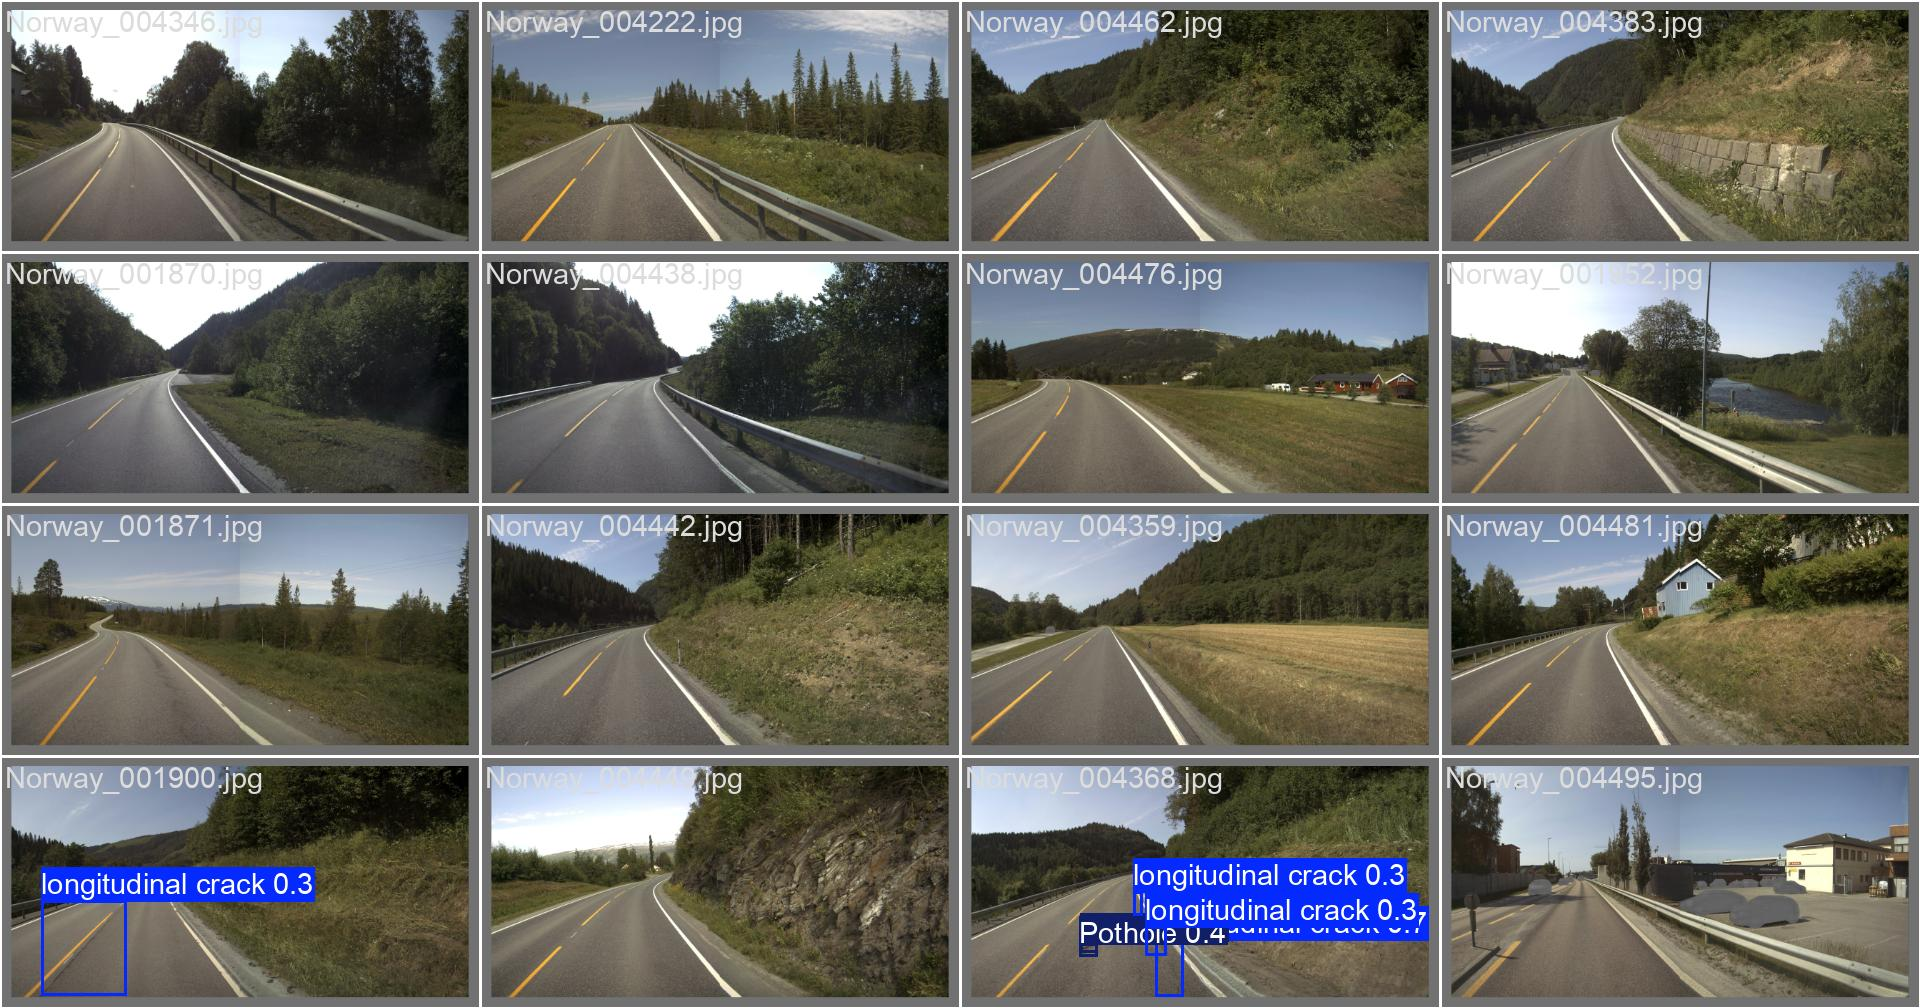


val_batch2_labels.jpg


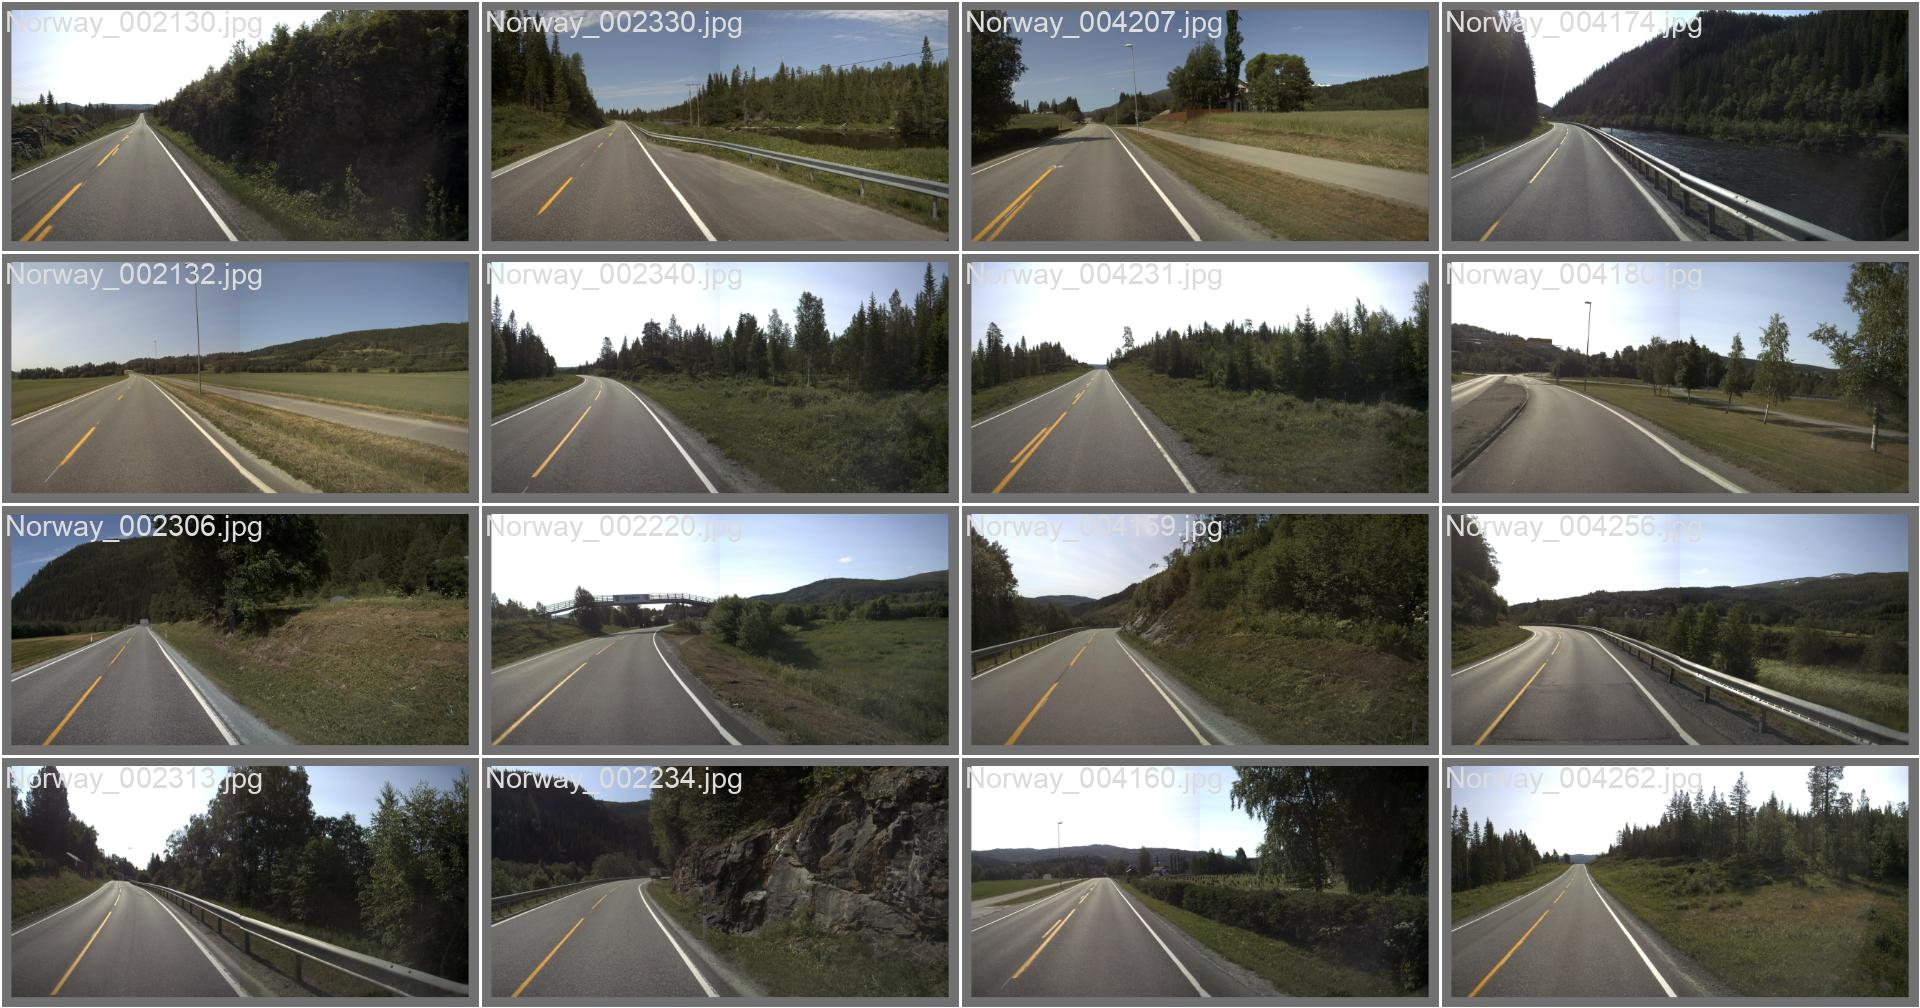


val_batch2_pred.jpg


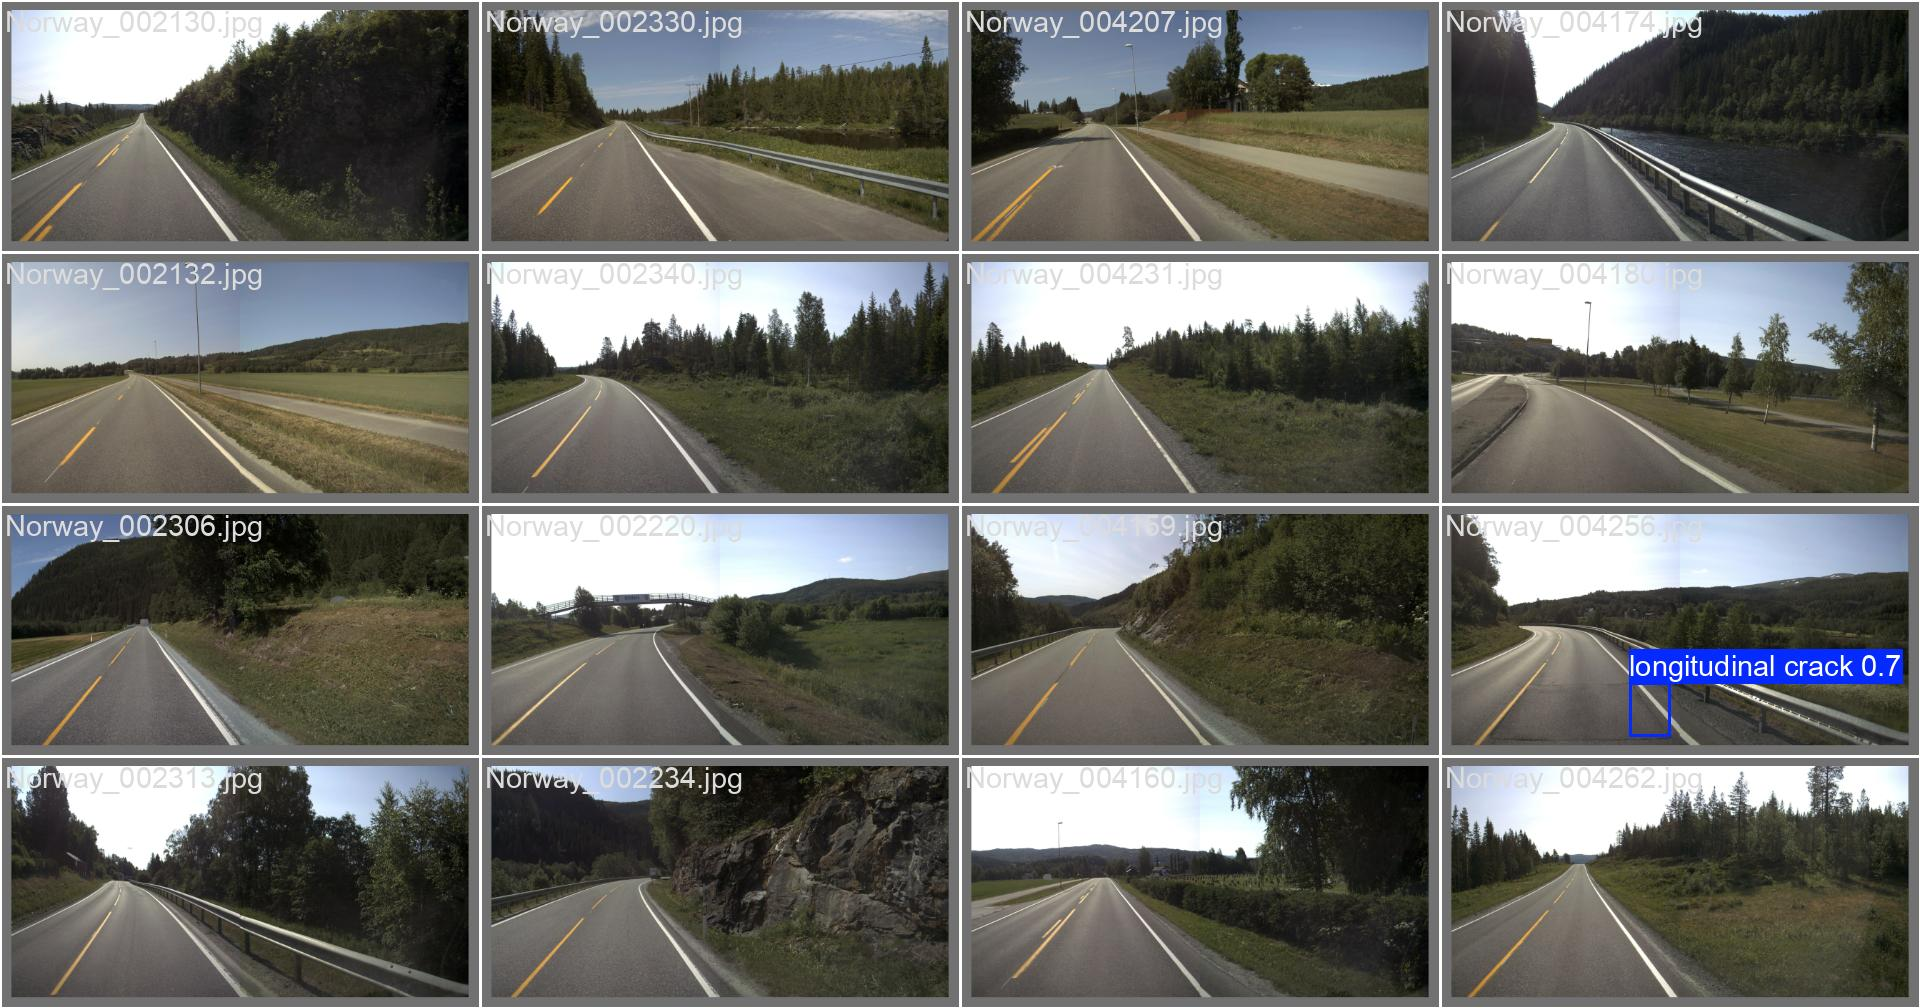

In [72]:
prediction_files = [
    "val_batch0_labels.jpg",
    "val_batch0_pred.jpg",
    "val_batch1_labels.jpg",
    "val_batch1_pred.jpg",
    "val_batch2_labels.jpg",
    "val_batch2_pred.jpg"
]

for filename in prediction_files:
    file_path = RUN_DIRECTORY / filename

    if file_path.exists():
        print(f"\n{filename}")

        display(
            Image(
                filename=str(file_path)
            )
        )